# Subsequent arm injury in MLB pitchers: fastball velocity, EWMA-CUSUM charts and a per-game model (v3)

**What changed from v2.** v2 (arm → subsequent arm, 2021–2024) found no chart that beat chance in a
permutation test, with about 25 training cases, enough only to detect large effects (AUC ≳ 0.7). v3:

1. **Broadens the injury definition to the throwing arm**, for both the initial and the subsequent
   placement (`INITIAL_GROUP`, `SUBSEQUENT_GROUP` in Settings; either can be set back to `"arm"`).
2. **Adds a games-since-return comparison** (Section 13): cases and controls lined up from their return,
   to see whether "coming back above baseline, then fading" is specific to cases or what every returner does.
3. **Adds a per-game model** (Section 14) that does not assume velocity relates to risk in one direction:
   velocity level as a spline (U-shape allowed), recent change from his own post-return games, workload,
   rest, role and time since return, with pitcher-clustered intervals.

Everything from v2 (length-matched charts, permutation test, leave-one-season-out, role adjustment) runs
unchanged on the arm cohort. The held-out season stays off (`RUN_HELDOUT = False`). Outputs go to
`data/arm_ewma_cusum_v3/`.

**Cohort and outcome**

| | Definition |
|---|---|
| Unit | One pitcher-season with an arm IL placement (the first that season), first return by August 31, at least 5 post-return appearances |
| Case | The first non-COVID IL placement after the return, that season, is for the arm |
| Control | No such placement. If the next placement is for something else (oblique, hamstring, ...), he stays a control and monitoring **stops at that IL date** |
| "Arm" | Arm, forearm, UCL / Tommy John, ulnar nerve, flexor / pronator, epicondyle, olecranon, valgus, internal brace, shoulder, rotator cuff, labrum, biceps, triceps, "arm", lat / latissimus, teres, thoracic outlet, shoulder capsule. Hand, finger, blister and wrist are **not** arm (the replication notebook's rule). "Non-throwing" excluded |

**Statistics, one value per game**, from the primary fastball (four-seam or sinker), games with at least
8 primary fastballs: **CV** (upper-sided chart) and **mean velocity** (lower-sided chart).

**Chart.** The EWMA-CUSUM of the NBA study, $c_j = \min\{0, \lambda(\text{PCI}_{\text{lower},j}-2) + (1-\lambda)c_{j-1}\}$
for velocity and its upper-sided mirror for CV, on $z_j=(x_j-\mu_0)/\sigma_0$. Baselines: Approach B
(empirical-Bayes shrinkage of the pre-injury mean, here toward the **role** mean), fit on training seasons.

Run top to bottom. All rules are in the Settings cell.

## 1. Settings

In [30]:
from pathlib import Path
import io
import re
import time
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

WORKSPACE = Path.cwd()
DATA_DIR = WORKSPACE / "data"
DATA_DIR.mkdir(exist_ok=True)
STATCAST_CACHE = DATA_DIR / "statcast"              # shared with the replication notebook
STATCAST_CACHE.mkdir(exist_ok=True)
CHADWICK_CACHE = DATA_DIR / "chadwick_register_ids.csv"
OUT_DIR = DATA_DIR / "arm_ewma_cusum_v3"
OUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
INJURY_WORKBOOK = WORKSPACE / "MLB Injuries Raw Data.xlsx"
if not INJURY_WORKBOOK.exists():
    raise FileNotFoundError(f"Expected workbook was not found: {INJURY_WORKBOOK}")

# ---- Seasons ----
TRAIN_SEASONS = [2021, 2022, 2023, 2024, 2025]
TEST_SEASON = 2026                  # held out: used once, in Section 13
RUN_HELDOUT = True                 # keep False until the design is final
SEASONS = TRAIN_SEASONS + [TEST_SEASON]

# ---- Cohort rules ----
PITCHER_POSITIONS = {"RP", "SP", "SP/RP", "RP/SP", "P"}
FIRST_RETURN_CUTOFF = "08-31"       # first return by August 31 (as in the WHIP paper)
MIN_POST_RETURN_APPS = 5            # at least 5 post-return appearances (as in the WHIP paper)
PATTERNS = {
    "elbow": re.compile(r"elbow|\bucl\b|ulnar|tommy john|flexor|pronator|forearm|epicondyl|olecranon|"
                        r"valgus|internal brace", flags=re.IGNORECASE),
    "arm":   re.compile(r"elbow|\bucl\b|ulnar|tommy john|flexor|pronator|forearm|epicondyl|olecranon|"
                        r"valgus|internal brace|shoulder|rotator|labrum|\bbicep|\btricep|\barm\b|\blat\b|"
                        r"latissimus|teres|thoracic outlet|capsul", flags=re.IGNORECASE),
}
INITIAL_GROUP = "arm"               # "arm" or "elbow": which initial IL placements define the cohort
SUBSEQUENT_GROUP = "arm"            # "arm" or "elbow": which later placement counts as a case
OUTCOME_LABEL = SUBSEQUENT_GROUP    # used in figure titles
COVID_PATTERN = re.compile(r"covid", flags=re.IGNORECASE)

# ---- Game-level statistics ----
FASTBALLS = ["FF", "SI"]            # primary fastball = whichever he threw more before the injury
LOOKBACK_DAYS = 365                 # baseline window before the initial arm injury
MIN_FB_GAME = 8                     # a game needs >= 8 primary fastballs to give a mean / SD / CV
CV_FIRST_N = None                   # e.g. 20 = use only his first 20 primary fastballs in each game
SIGMA_MODES = ["pooled", "per_fb"]  # pooled SD (NBA study) and SD scaled by 1/sqrt(fastballs in the game)

METRICS = {
    "cv":   {"label": "Fastball velocity CV (%)",     "side": "upper"},   # signal on a rise
    "velo": {"label": "Mean fastball velocity (mph)", "side": "lower"},   # signal on a drop
}

# ---- Chart grid (NBA study) ----
LAMBDA_GRID = np.round(np.arange(0.45, 0.951, 0.10), 2)           # 0.45 ... 0.95
LAMBDA_GRID_LOW = np.round(np.arange(0.05, 0.351, 0.10), 2)       # sensitivity check: 0.05 ... 0.35
H_GRID_NBA = np.round(np.arange(0.05, 0.501, 0.05), 2)            # NBA grid, 0.05 ... 0.50 (reported for reference)
H_GRID_WIDE = np.round(np.r_[np.arange(0.05, 0.501, 0.05), np.arange(0.75, 5.001, 0.25)], 2)  # selection grid
# Selection: highest matched Youden on the training seasons (accuracy favours never signalling at ~17% cases)
N_PERM = 500                        # label shuffles for the permutation test
HAZARD_K = 3                        # per-game analyses: subsequent IL within the next 3 appearances
REST_CAP = 10                       # days of rest are capped at 10 in the per-game model
N_BOOT = 1000                       # pitcher-clustered bootstrap resamples
MATCH_WITHIN_ROLE = True            # compare each case only with controls of the same role
SHRINK_BY_ROLE = True               # shrink each pitcher toward his role's mean (starter / reliever / mixed)
MIN_UNITS_ROLE_FIT = 10             # a role needs >= 10 training units for its own fit (else league-wide)

# ---- Block-bootstrap false-alarm check ----
N_NULL_SEQUENCES = 5000
BLOCK_LEN = 3
SEED = 2026

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    plt.show()


print("Training seasons:", TRAIN_SEASONS, "| held-out season:", TEST_SEASON)
print("Outputs:", OUT_DIR)

Training seasons: [2021, 2022, 2023, 2024, 2025] | held-out season: 2026
Outputs: /workspaces/Sports-Analytics-and-Intelligence-Lab/MLB Pitcher Injuries/data/arm_ewma_cusum_v3


## 2. Injury records

Loads every season sheet, keeps pitcher rows with an IL date, and classifies each description as arm /
not arm and COVID / not COVID. Pitchers are keyed by **FanGraphs ID** rather than name, so accented
names cannot break the join (the issue behind the Table 2 baseline row). If a sheet has no
`key_fangraphs` column, the ID is read from the FanGraphs URL.

For the baseline window, the injury date is the **earlier** of the injury/surgery date and the IL date.
This matters for stints carried over from a previous season (e.g. Tommy John surgery the year before):
their IL date is opening day, but the pre-injury games are the ones before the surgery.

In [2]:
def clean_id(value):
    """IDs as plain strings: 12447.0 -> '12447', ' sa3012 ' -> 'sa3012'."""
    if pd.isna(value):
        return None
    text = str(value).strip()
    if not text:
        return None
    return text[:-2] if text.endswith(".0") else text


def fangraphs_id(row):
    value = clean_id(row.get("key_fangraphs"))
    if value:
        return value
    for column in ["URL", "sub_url"]:
        text = row.get(column)
        if isinstance(text, str):
            match = (re.search(r"/players/[^/]+/([^/?#]+)", text)
                     or re.match(r"[^/]+/([^/?#]+)/", text))
            if match:
                return match.group(1)
    return None


excel_file = pd.ExcelFile(INJURY_WORKBOOK)
tables = []
for sheet in excel_file.sheet_names:
    try:
        season = int(str(sheet).strip())
    except ValueError:
        continue
    if season in SEASONS:
        table = pd.read_excel(excel_file, sheet_name=sheet)
        table["Season"] = season
        tables.append(table)
missing_sheets = sorted(set(SEASONS) - {int(t["Season"].iloc[0]) for t in tables if len(t)})
if missing_sheets:
    raise ValueError(f"Workbook has no sheet for seasons {missing_sheets}")

injuries = pd.concat(tables, ignore_index=True).rename(columns={
    "IL Retro Date": "IL_Date", "Return Date": "Return_Date",
    "Injury / Surgery": "Injury", "Injury / Surgery Date": "Injury_Date"})
for column in ["IL_Date", "Return_Date", "Injury_Date"]:
    if column not in injuries.columns:
        injuries[column] = pd.NaT
    injuries[column] = pd.to_datetime(injuries[column], errors="coerce")

injuries["Pos"] = injuries["Pos"].astype(str).str.strip().str.upper()
injuries["Injury"] = injuries["Injury"].fillna("").astype(str).str.strip()
injuries["FanGraphs_ID"] = injuries.apply(fangraphs_id, axis=1)
injuries["pkey"] = injuries["FanGraphs_ID"].where(injuries["FanGraphs_ID"].notna(),
                                                  "name:" + injuries["Name"].astype(str))
injuries = injuries.loc[injuries["Pos"].isin(PITCHER_POSITIONS) & injuries["IL_Date"].notna()].copy()
injuries = injuries.drop_duplicates(["pkey", "Season", "IL_Date", "Injury"])
injuries["is_covid"] = injuries["Injury"].str.contains(COVID_PATTERN)
non_throwing = injuries["Injury"].str.contains("non-throwing", case=False)
for group, pattern in PATTERNS.items():
    injuries[f"is_{group}"] = injuries["Injury"].str.contains(pattern) & ~non_throwing
injuries["is_initial"] = injuries[f"is_{INITIAL_GROUP}"]
injuries["is_subseq"] = injuries[f"is_{SUBSEQUENT_GROUP}"]
injuries["onset"] = injuries[["Injury_Date", "IL_Date"]].min(axis=1)
injuries = injuries.sort_values(["pkey", "Season", "IL_Date"], kind="stable").reset_index(drop=True)

display(injuries.groupby("Season").agg(pitcher_IL_rows=("pkey", "size"),
                                      initial_type_rows=("is_initial", "sum"),
                                      subsequent_type_rows=("is_subseq", "sum"),
                                      covid_rows=("is_covid", "sum"),
                                      missing_fangraphs_id=("FanGraphs_ID", lambda s: int(s.isna().sum()))))

# Every description and how it was classified, for a line-by-line check of the rule.
classification_review = (injuries.loc[~injuries["is_covid"]]
                         .groupby(["is_arm", "is_elbow", "Injury"]).size().rename("IL rows").reset_index()
                         .sort_values(["is_arm", "is_elbow", "IL rows"], ascending=[False, False, False]))
classification_review.to_csv(OUT_DIR / "injury_classification_review.csv", index=False)
print(f"Initial injury group: {INITIAL_GROUP} | subsequent injury group: {SUBSEQUENT_GROUP}")
print("Arm descriptions (is_elbow marks the elbow subset):")
with pd.option_context("display.max_rows", 300):
    display(classification_review.loc[classification_review["is_arm"]])
print("Most common non-arm descriptions (full list in injury_classification_review.csv):")
display(classification_review.loc[~classification_review["is_arm"]].head(30))

,pitcher_IL_rows,initial_type_rows,subsequent_type_rows,covid_rows,missing_fangraphs_id
Season,,,,,
2021,687,303,303,130,0
2022,559,285,285,10,0
2023,502,293,293,2,0
2024,483,320,320,2,0
2025,458,292,292,0,0
2026,487,305,305,0,0


Initial injury group: arm | subsequent injury group: arm
Arm descriptions (is_elbow marks the elbow subset):


,is_arm,is_elbow,Injury,IL rows
517,True,True,Tommy John surgery,300
434,True,True,Elbow inflammation,158
511,True,True,Strained forearm,76
425,True,True,Elbow discomfort,34
505,True,True,Sprained elbow,33
462,True,True,Elbow surgery (internal brace),26
488,True,True,Forearm inflammation,26
506,True,True,Strained elbow,26
508,True,True,Strained elbow flexor,20
518,True,True,Tommy John surgery (internal brace),19


Most common non-arm descriptions (full list in injury_classification_review.csv):


,is_arm,is_elbow,Injury,IL rows
266,False,False,Strained oblique,122
256,False,False,Strained hamstring,104
255,False,False,Strained groin,82
310,False,False,Undisclosed,63
261,False,False,Strained lower back,51
247,False,False,Strained calf,38
144,False,False,Knee inflammation,33
227,False,False,Sprained ankle,24
126,False,False,Hip impingement,18
127,False,False,Hip inflammation,18


## 3. Cohort: initial arm IL placement → subsequent arm IL placement

For each pitcher-season, the **initial** placement is his first arm placement of that season. The
**next** non-COVID placement after his return decides the outcome: arm → case (chart runs up to that IL
date); anything else → control, chart stops at that IL date; none → control, chart runs to the end of the
season.

In [3]:
initial_rows = injuries.loc[injuries["is_initial"] & ~injuries["is_covid"]]
units = (initial_rows.groupby(["pkey", "Season"], as_index=False, sort=False).head(1)
              [["pkey", "Name", "Season", "FanGraphs_ID", "Team", "Pos", "Injury", "Injury_Date",
                "IL_Date", "onset", "Return_Date"]]
              .rename(columns={"Injury": "initial_injury"})
              .reset_index(drop=True))
funnel = [("Pitcher-seasons with an arm IL placement", len(units))]

cutoff = pd.to_datetime(units["Season"].astype(str) + "-" + FIRST_RETURN_CUTOFF)
units = units.loc[units["Return_Date"].notna()]
funnel.append(("... with a return date", len(units)))
units = units.loc[units["Return_Date"] >= units["IL_Date"]]
funnel.append(("... return on or after the IL date", len(units)))
units = units.loc[units["Return_Date"] <= cutoff.loc[units.index]].copy()
funnel.append((f"... first return by {FIRST_RETURN_CUTOFF}", len(units)))

# Next non-COVID IL placement after the return, same season.
later = injuries.loc[~injuries["is_covid"], ["pkey", "Season", "IL_Date", "Injury", "is_subseq"]].merge(
    units[["pkey", "Season", "Return_Date"]], on=["pkey", "Season"])
later = later.loc[later["IL_Date"] > later["Return_Date"]].sort_values(["pkey", "Season", "IL_Date"])
next_il = later.groupby(["pkey", "Season"], as_index=False).head(1)
any_later_subseq = later.loc[later["is_subseq"]].groupby(["pkey", "Season"]).size().rename("n_later_subseq")

units = units.merge(next_il[["pkey", "Season", "IL_Date", "Injury", "is_subseq"]]
                    .rename(columns={"IL_Date": "next_il_date", "Injury": "next_injury",
                                     "is_subseq": "next_is_subseq"}),
                    on=["pkey", "Season"], how="left")
units = units.merge(any_later_subseq, left_on=["pkey", "Season"], right_index=True, how="left")
units["next_is_subseq"] = units["next_is_subseq"].astype("boolean").fillna(False).astype(bool)
units["case"] = units["next_is_subseq"].astype(int)
units["event_date"] = units["next_il_date"].where(units["case"] == 1)
units["censor_date"] = units["next_il_date"].where(units["case"] == 0)
units["stop_date"] = units["next_il_date"].fillna(pd.to_datetime(units["Season"].astype(str) + "-12-31")
                                                  + pd.Timedelta(days=1))
units["outcome"] = np.select(
    [units["case"] == 1, units["censor_date"].notna()],
    ["case: subsequent arm IL", "control: stopped at non-arm IL"],
    default="control: no later IL")

n_subseq_after_other = int(((units["case"] == 0) & units["n_later_subseq"].notna()).sum())
print("Controls whose next placement was non-arm but who had an arm placement later that season:",
      n_subseq_after_other, "(kept as controls, as specified)")
display(pd.crosstab(units["Season"], units["outcome"], margins=True))

Controls whose next placement was non-arm but who had an arm placement later that season: 8 (kept as controls, as specified)


outcome,case: subsequent arm IL,control: no later IL,control: stopped at non-arm IL,All
Season,,,,
2021,32,75,22,129
2022,28,64,19,111
2023,23,74,19,116
2024,33,78,15,126
2025,27,63,17,107
2026,21,87,14,122
All,164,441,106,711


## 4. MLBAM IDs and Baseball Savant pitch data

Statcast uses MLBAM IDs, linked to FanGraphs IDs by the Chadwick register (cached by the replication
notebook; downloaded here if missing). Each pitcher's window runs from 365 days before the initial arm
injury to November 30 of the monitored season. Cached files from the replication notebook are used when
they cover the window; otherwise only the missing earlier dates are downloaded and cached as a separate
file.

In [4]:
CHADWICK_URL = "https://raw.githubusercontent.com/chadwickbureau/register/master/data/people-{}.csv"
if CHADWICK_CACHE.exists():
    id_map = pd.read_csv(CHADWICK_CACHE, dtype=str)
else:
    parts = []
    for suffix in "0123456789abcdef":
        part = pd.read_csv(CHADWICK_URL.format(suffix), usecols=["key_mlbam", "key_fangraphs"],
                           dtype=str, low_memory=False)
        parts.append(part.dropna())
        time.sleep(0.5)
    id_map = pd.concat(parts, ignore_index=True)
    id_map.to_csv(CHADWICK_CACHE, index=False)
fg_to_mlbam = dict(zip(id_map["key_fangraphs"].map(clean_id), id_map["key_mlbam"].map(clean_id)))

units["mlbam"] = units["FanGraphs_ID"].map(lambda v: fg_to_mlbam.get(v) if v else None)
no_id = units.loc[units["mlbam"].isna(), ["Name", "Season", "FanGraphs_ID"]]
if len(no_id):
    print("No MLBAM ID (dropped):")
    display(no_id)
units = units.loc[units["mlbam"].notna()].copy()
units["mlbam"] = units["mlbam"].astype(int)
funnel.append(("... with an MLBAM ID", len(units)))
units["window_start"] = (units["onset"] - pd.Timedelta(days=LOOKBACK_DAYS)).dt.normalize()
units["window_end"] = pd.to_datetime(units["Season"].astype(str) + "-11-30")
print("Pitcher-seasons to download:", len(units))

No MLBAM ID (dropped):


,Name,Season,FanGraphs_ID
604,Coleman Crow,2026,27926
605,Wilber Dotel,2026,28901
606,Kendry Rojas,2026,29423
628,Marco Raya,2026,30166
661,Tatsuya Imai,2026,37124
708,Dylan File,2021,sa3004197
709,Shane Drohan,2024,sa3014447
710,Daniel Tillo,2021,sa876284


Pitcher-seasons to download: 703


In [5]:
SAVANT_URL = (
    "https://baseballsavant.mlb.com/statcast_search/csv?all=true&type=details&player_type=pitcher"
    "&hfGT=R%7C&hfSea=&game_date_gt={start}&game_date_lt={end}&pitchers_lookup%5B%5D={mlbam}"
    "&min_pitches=0&min_results=0&min_abs=0&group_by=name&sort_col=pitches&sort_order=desc"
)
SAVANT_KEEP = ["pitcher", "game_pk", "game_date", "game_type", "inning", "at_bat_number",
               "pitch_number", "pitch_type", "release_speed", "p_throws"]
CACHE_NAME = re.compile(r"(\d+)_(\d{8})_(\d{8})\.csv")


def download_statcast(mlbam, start, end, sleep_seconds=2.0, retries=3):
    """One Savant request (regular season), saved in the shared cache with the same file naming."""
    path = STATCAST_CACHE / f"{mlbam}_{start:%Y%m%d}_{end:%Y%m%d}.csv"
    if path.exists():
        return pd.read_csv(path)
    url = SAVANT_URL.format(mlbam=mlbam, start=f"{start:%Y-%m-%d}", end=f"{end:%Y-%m-%d}")
    for attempt in range(1, retries + 1):
        try:
            time.sleep(sleep_seconds)
            request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urlopen(request, timeout=120) as response:
                text = response.read().decode("utf-8-sig")
            break
        except Exception as error:
            print(f"  attempt {attempt} failed for {mlbam}: {error!r}")
            time.sleep(10 * attempt)
    else:
        raise RuntimeError(f"Could not download Statcast data for pitcher {mlbam}")
    data = pd.read_csv(io.StringIO(text)) if text.strip() else pd.DataFrame(columns=SAVANT_KEEP)
    required = set(SAVANT_KEEP) - {"p_throws"}
    if len(data) and required - set(data.columns):
        raise ValueError(f"Unexpected Savant response for {mlbam}: {text[:300]!r}")
    if "game_type" in data.columns:
        data = data.loc[data["game_type"] == "R"]
    data = data[[c for c in SAVANT_KEEP if c in data.columns]]
    data.to_csv(path, index=False)
    return data


def cached_files(mlbam):
    out = []
    for path in STATCAST_CACHE.glob(f"{mlbam}_*.csv"):
        match = CACHE_NAME.fullmatch(path.name)
        if match and int(match.group(1)) == mlbam:
            out.append((pd.Timestamp(match.group(2)), pd.Timestamp(match.group(3)), path))
    return out


def statcast_window(mlbam, start, end):
    """Pitches for [start, end], from the cache where possible; downloads only the uncovered part."""
    files = cached_files(mlbam)
    pieces = [pd.read_csv(p) for s, e, p in files if s <= end and e >= start]   # overlapping files
    covered_from = min([s for s, e, p in files if s <= end and e >= end], default=None)
    if covered_from is None:                       # nothing reaches the end date: one full request
        pieces.append(download_statcast(mlbam, start, end))
    elif covered_from > start:                     # fetch only the earlier, uncovered dates
        pieces.append(download_statcast(mlbam, start, covered_from - pd.Timedelta(days=1)))
    pieces = [p for p in pieces if len(p)]
    if not pieces:
        return pd.DataFrame(columns=SAVANT_KEEP)
    data = pd.concat(pieces, ignore_index=True)
    data["game_date"] = pd.to_datetime(data["game_date"])
    return data.loc[data["game_date"].between(start, end)]


pieces, statcast_failures = [], []
for number, (_, row) in enumerate(units.drop_duplicates(["mlbam", "window_start", "window_end"]).iterrows(), 1):
    try:
        pieces.append(statcast_window(row["mlbam"], row["window_start"], row["window_end"]))
    except Exception as error:
        statcast_failures.append({"Name": row["Name"], "Season": row["Season"], "mlbam": row["mlbam"],
                                  "error": repr(error)})
    if number % 50 == 0:
        print(f"{number} windows ({len(statcast_failures)} failures)")
statcast_failures = pd.DataFrame(statcast_failures)
statcast_failures.to_csv(OUT_DIR / "statcast_fetch_failures.csv", index=False)
if len(statcast_failures):
    display(statcast_failures)

pitches = pd.concat(pieces, ignore_index=True)
if "p_throws" not in pitches.columns:
    pitches["p_throws"] = np.nan
pitches = pitches.dropna(subset=["game_pk", "at_bat_number", "pitch_number"]).copy()
pitches["pitcher"] = pitches["pitcher"].astype(int)
pitches["game_pk"] = pitches["game_pk"].astype(int)
pitches["game_date"] = pd.to_datetime(pitches["game_date"])
pitches = (pitches.drop_duplicates(["pitcher", "game_pk", "at_bat_number", "pitch_number"])
                  .sort_values(["pitcher", "game_date", "game_pk", "at_bat_number", "pitch_number"])
                  .reset_index(drop=True))
pitches["pitch_count"] = pitches.groupby(["pitcher", "game_pk"]).cumcount() + 1
pitches_by_pitcher = {p: g for p, g in pitches.groupby("pitcher")}
print(f"Pitches: {len(pitches):,} | pitchers: {pitches['pitcher'].nunique()}")

50 windows (2 failures)
100 windows (4 failures)
150 windows (6 failures)
200 windows (10 failures)
250 windows (17 failures)
300 windows (20 failures)
350 windows (23 failures)
400 windows (31 failures)
450 windows (35 failures)
500 windows (46 failures)
550 windows (60 failures)
600 windows (63 failures)
650 windows (69 failures)
700 windows (75 failures)


,Name,Season,mlbam,error
0,Mike Minor,2022,501985,"NotImplementedError(""strftime not yet supporte..."
1,Tommy Kahnle,2023,592454,"NotImplementedError(""strftime not yet supporte..."
2,Dylan Floro,2022,571670,"NotImplementedError(""strftime not yet supporte..."
3,Lucas Sims,2022,608371,"NotImplementedError(""strftime not yet supporte..."
4,Josh Hader,2026,623352,"NotImplementedError(""strftime not yet supporte..."
...,...,...,...,...
70,Jay Jackson,2022,543351,"NotImplementedError(""strftime not yet supporte..."
71,Justin Verlander,2024,434378,"NotImplementedError(""strftime not yet supporte..."
72,Wade Miley,2022,489119,"NotImplementedError(""strftime not yet supporte..."
73,Wade Miley,2024,489119,"NotImplementedError(""strftime not yet supporte..."


Pitches: 999,047 | pitchers: 482


In [6]:
# Arm descriptions that name a side: flag any that do not match the throwing arm, for manual review.
throws = pitches.dropna(subset=["p_throws"]).groupby("pitcher")["p_throws"].agg(lambda s: s.mode().iat[0])
units["throws"] = units["mlbam"].map(throws)
side = units["initial_injury"].str.extract(r"\b(left|right)\b", flags=re.IGNORECASE, expand=False).str.upper().str[0]
side_check = units.assign(side=side).loc[lambda d: d["side"].notna()]
mismatch = side_check.loc[side_check["throws"].notna() & (side_check["side"] != side_check["throws"])]
print(f"Initial arm descriptions naming a side: {len(side_check)}; "
      f"side differs from the throwing arm: {len(mismatch)}")
if len(mismatch):
    display(mismatch[["Name", "Season", "initial_injury", "throws"]])

Initial arm descriptions naming a side: 0; side differs from the throwing arm: 0


## 5. Game-level fastball statistics

For each unit:

* **Primary fastball**: FF or SI, whichever he threw more in the 365 days before the injury (if he has no
  pre-injury fastballs, the post-return games decide).
* **Baseline games**: games in that pre-injury window with at least `MIN_FB_GAME` primary fastballs.
* **Monitored games**: games from the return date up to (not including) the stop date, with at least
  `MIN_FB_GAME` primary fastballs. Appearances with fewer fastballs leave the chart unchanged.
* **Post-return appearances** (for the 5-appearance rule) count every regular-season game after the return
  that season, as in the WHIP paper.

In [7]:
def per_game(game_pitches, primary):
    """Mean, SD and CV of the primary fastball, one row per game."""
    fb = game_pitches.loc[(game_pitches["pitch_type"] == primary) & game_pitches["release_speed"].notna()]
    if CV_FIRST_N:
        fb = fb.groupby("game_pk", sort=False).head(CV_FIRST_N)
    g = (fb.groupby("game_pk")
           .agg(game_date=("game_date", "first"), n_fb=("release_speed", "size"),
                velo=("release_speed", "mean"), sd=("release_speed", "std"))
           .reset_index().sort_values(["game_date", "game_pk"]))
    g["cv"] = 100 * g["sd"] / g["velo"]
    g["n_pitches"] = g["game_pk"].map(game_pitches.groupby("game_pk").size())
    return g.loc[g["n_fb"] >= MIN_FB_GAME].reset_index(drop=True)


unit_data, drop_reason = {}, {}
units = units.reset_index(drop=True)
units["uid"] = units.index
for _, row in units.iterrows():
    g = pitches_by_pitcher.get(row["mlbam"])
    if g is None:
        drop_reason[row["uid"]] = "no Statcast pitches"
        continue
    season_end = pd.Timestamp(f"{int(row['Season'])}-12-31")
    pre = g.loc[(g["game_date"] >= row["window_start"]) & (g["game_date"] < row["onset"])]
    post = g.loc[(g["game_date"] >= row["Return_Date"]) & (g["game_date"] <= season_end)]
    monitored_raw = post.loc[post["game_date"] < row["stop_date"]]

    fb_counts = pre.loc[pre["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        fb_counts = monitored_raw.loc[monitored_raw["pitch_type"].isin(FASTBALLS), "pitch_type"].value_counts()
    if fb_counts.empty:
        drop_reason[row["uid"]] = "no four-seam or sinker"
        continue
    primary = fb_counts.idxmax()

    apps = post.drop_duplicates("game_pk")[["game_pk", "game_date"]].sort_values(["game_date", "game_pk"])
    if len(apps) < MIN_POST_RETURN_APPS:
        drop_reason[row["uid"]] = f"fewer than {MIN_POST_RETURN_APPS} post-return appearances"
        continue
    apps_before_stop = apps.loc[apps["game_date"] < row["stop_date"]].reset_index(drop=True)
    monitored = per_game(monitored_raw, primary)
    if monitored.empty:
        drop_reason[row["uid"]] = "no monitored game with enough fastballs"
        continue
    pre_games = pre.groupby("game_pk")["inning"].min()
    ref_games = pre_games if len(pre_games) else monitored_raw.groupby("game_pk")["inning"].min()
    start_share = (ref_games == 1).mean() if len(ref_games) else np.nan
    role = ("unknown" if np.isnan(start_share) else "starter" if start_share >= 0.6
            else "reliever" if start_share <= 0.2 else "mixed")
    app_index = {pk: i for i, pk in enumerate(apps_before_stop["game_pk"])}
    monitored["app_index"] = monitored["game_pk"].map(app_index)      # 0 = first appearance back
    rest = apps_before_stop["game_date"].diff().dt.days.fillna(REST_CAP)   # first game back = long rest
    monitored["rest_days"] = monitored["game_pk"].map(dict(zip(apps_before_stop["game_pk"], rest)))
    unit_data[row["uid"]] = {
        "primary": primary,
        "role": role,
        "baseline": per_game(pre, primary),
        "monitored": monitored,
        "n_apps_before_stop": len(apps_before_stop),
        "n_post_return_apps": len(apps),
    }

units["dropped"] = units["uid"].map(drop_reason)
for reason, n in units["dropped"].value_counts().items():
    print(f"Dropped: {reason}: {n}")
units = units.loc[units["dropped"].isna()].drop(columns="dropped")   # index stays = uid
funnel.append((f"... with Statcast data, >= {MIN_POST_RETURN_APPS} post-return appearances, "
               "and >= 1 monitored game", len(units)))
units["split"] = np.where(units["Season"].isin(TRAIN_SEASONS), "train", "test")
units["primary"] = units["uid"].map(lambda u: unit_data[u]["primary"])
units["role"] = units["uid"].map(lambda u: unit_data[u]["role"])
units["baseline_games"] = units["uid"].map(lambda u: len(unit_data[u]["baseline"]))
units["monitored_games"] = units["uid"].map(lambda u: len(unit_data[u]["monitored"]))

funnel = pd.DataFrame(funnel, columns=["step", "pitcher-seasons"])
funnel.to_csv(OUT_DIR / "cohort_funnel.csv", index=False)
display(funnel)
cohort_table = (units.groupby(["split", "Season"])
                     .agg(units=("uid", "size"), cases=("case", "sum"),
                          controls_stopped_at_other_IL=("censor_date", lambda s: int(s.notna().sum())),
                          median_baseline_games=("baseline_games", "median"),
                          no_baseline_games=("baseline_games", lambda s: int((s == 0).sum())),
                          median_monitored_games=("monitored_games", "median")))
display(cohort_table)
display(pd.crosstab([units["split"], units["role"]], units["case"].map({1: "case", 0: "control"})))
units.drop(columns=["window_start", "window_end"]).to_csv(OUT_DIR / "cohort_units.csv", index=False)

Dropped: fewer than 5 post-return appearances: 124
Dropped: no Statcast pitches: 46
Dropped: no four-seam or sinker: 23
Dropped: no monitored game with enough fastballs: 22


,step,pitcher-seasons
0,Pitcher-seasons with an arm IL placement,1590
1,... with a return date,1284
2,... return on or after the IL date,1283
3,... first return by 08-31,711
4,... with an MLBAM ID,703
5,"... with Statcast data, >= 5 post-return appea...",488


units  cases  controls_stopped_at_other_IL  \
split Season                                               
test  2026       84     12                            13   
train 2021       88     20                            16   
      2022       78     19                            15   
      2023       77     15                            14   
      2024       82     21                            10   
      2025       79     22                            11   

              median_baseline_games  no_baseline_games  median_monitored_games  
split Season                                                                    
test  2026                     19.0                  2                     9.0  
train 2021                     14.0                  3                     7.5  
      2022                     19.0                  1                     8.0  
      2023                     19.0                  5                     8.0  
      2024                     20.5                  4                     8.0  
      2025                     19.0                  5                     8.0

case            case  control
split role                   
test  mixed        0        1
      reliever     7       44
      starter      5       27
train mixed        8       10
      reliever    47      162
      starter     42      135

## 6. Baselines (Approach B: empirical-Bayes shrinkage, training seasons only)

For each statistic, the grand mean $G$, the pooled within-pitcher variance $\sigma^2_w$ (ANOVA
$SS_W/df_W$) and the between-pitcher variance $\sigma^2_b$ (Henderson's Method I) come from the
**baseline games of training-season units**. Each unit then gets

$$\mu_0 = \frac{n_i \bar x_i + k G}{n_i + k},\qquad k = \sigma^2_w / \sigma^2_b,$$

where $n_i$ and $\bar x_i$ are his own baseline games. A unit with no baseline games gets $\mu_0 = G$.
Held-out units use the same frozen $G$, $k$ and $\sigma_0$.

**Shrink toward the role mean** (`SHRINK_BY_ROLE = True`). Starters' game CV is naturally higher than
relievers' (fatigue fade over 90 pitches adds spread). When between-pitcher variance is small, shrinkage
pulls everyone toward one league mean, so starters sit above their baseline in every game, and charts
alarm on role rather than injury. Fitting $G$, $k$ and $\sigma$ separately for starters, relievers and
mixed-role pitchers (each with at least `MIN_UNITS_ROLE_FIT` training units) removes that.

**Two versions of the game SD, run side by side** (each statistic × SD version is one "chart"):

* `pooled` — one $\sigma_0$ for every game (the NBA study).
* `per_fb` — each game's SD depends on how many primary fastballs he threw:
  $\sigma_j = \sqrt{\tau^2 + s^2/n_{fb,j}}$. $\tau^2$ is game-to-game variation that more fastballs do
  not remove (a pitcher's level shifts from day to day); $s^2/n_{fb}$ is the part that does. Both are
  estimated from training baseline games by regressing squared within-pitcher deviations on $1/n_{fb}$.
  A 9-fastball reliever outing therefore counts for less than a 50-fastball start, without treating a
  long start as nearly noise-free.

In [8]:
def fit_shrinkage(frames, value):
    """Henderson Method I on baseline games. frames: list of per-unit baseline DataFrames."""
    groups = [f for f in frames if len(f) >= 1]
    y = [f[value].to_numpy(float) for f in groups]
    w = [f["n_fb"].to_numpy(float) for f in groups]
    n = np.array([len(v) for v in y], float)
    N, a = n.sum(), len(y)
    grand = np.concatenate(y).mean()
    means = np.array([v.mean() for v in y])
    df_w = N - a
    ms_w = sum(((v - v.mean()) ** 2).sum() for v in y) / df_w
    ms_b = (n * (means - grand) ** 2).sum() / (a - 1)
    n0 = (N - (n ** 2).sum() / N) / (a - 1)
    var_b = max((ms_b - ms_w) / n0, 0.0)
    k = ms_w / var_b if var_b > 0 else np.inf
    # Per-game variance model: Var(game value) = tau^2 + s^2 / n_fb  (a game-to-game part that does not
    # shrink with more fastballs, plus a part that does). Least squares of squared within-pitcher
    # deviations (df-corrected) on 1 / n_fb, both components kept >= 0.
    r2 = np.concatenate([((v - v.mean()) ** 2) * len(v) / (len(v) - 1) for v in y if len(v) >= 2])
    inv_n = np.concatenate([1 / wi for v, wi in zip(y, w) if len(v) >= 2])
    X = np.column_stack([np.ones_like(inv_n), inv_n])
    tau2, s2 = np.linalg.lstsq(X, r2, rcond=None)[0]
    if s2 < 0:
        tau2, s2 = r2.mean(), 0.0
    elif tau2 < 0:
        tau2, s2 = 0.0, (r2 * inv_n).sum() / (inv_n ** 2).sum()
    return {"grand_mean": grand, "sigma_w": np.sqrt(ms_w), "sigma_b": np.sqrt(var_b), "k": k,
            "tau": np.sqrt(tau2), "s_per_fb": np.sqrt(s2), "units": a, "games": int(N)}


def shrunk_mean(baseline, value, fit):
    n_i = len(baseline)
    if n_i == 0 or not np.isfinite(fit["k"]):
        return fit["grand_mean"]
    return (n_i * baseline[value].mean() + fit["k"] * fit["grand_mean"]) / (n_i + fit["k"])


toy = [pd.DataFrame({"x": [1.0, 2.0, 3.0], "n_fb": 10}), pd.DataFrame({"x": [3.0, 2.0, 1.0], "n_fb": 10})]
toy_fit = fit_shrinkage(toy, "x")
assert toy_fit["k"] == np.inf and abs(shrunk_mean(toy[0], "x", toy_fit) - 2.0) < 1e-12
assert abs(toy_fit["sigma_w"] - 1.0) < 1e-12

CHARTS = {f"{m}|{mode}": {"stat": m, "mode": mode,
                          "label": f"{METRICS[m]['label']} — {'pooled SD' if mode == 'pooled' else 'per-fastball SD'}"}
          for m in METRICS for mode in SIGMA_MODES}

train_uids = units.loc[units["split"] == "train", "uid"].tolist()
test_uids = units.loc[units["split"] == "test", "uid"].tolist()
fits_all = {m: fit_shrinkage([unit_data[u]["baseline"] for u in train_uids], m) for m in METRICS}
fits_role = {}
if SHRINK_BY_ROLE:
    for role in ["starter", "reliever", "mixed"]:
        ru = [u for u in train_uids if unit_data[u]["role"] == role and len(unit_data[u]["baseline"])]
        if len(ru) >= MIN_UNITS_ROLE_FIT:
            fits_role[role] = {m: fit_shrinkage([unit_data[u]["baseline"] for u in ru], m) for m in METRICS}


def fit_for(u, m):
    """Role-specific fit if available (SHRINK_BY_ROLE), otherwise the league-wide fit."""
    return fits_role.get(unit_data[u]["role"], fits_all)[m]


fit_table = pd.concat({"all": pd.DataFrame(fits_all).T,
                       **{r: pd.DataFrame(f).T for r, f in fits_role.items()}}, names=["fit", "statistic"])
fit_table.to_csv(OUT_DIR / "baseline_fits.csv")
display(fit_table.round(4))
print("Roles with their own fit:", list(fits_role) or "none (league-wide fit for everyone)")


def game_sigma(frame, fit, mode):
    if mode == "per_fb":
        return np.sqrt(fit["tau"] ** 2 + fit["s_per_fb"] ** 2 / frame["n_fb"].to_numpy(float))
    return np.full(len(frame), fit["sigma_w"])


for u in units["uid"]:
    d = unit_data[u]
    d["mu0"], d["z"], d["dev"], d["baseline_dev"], d["sigma"] = {}, {}, {}, {}, {}
    for m, spec in METRICS.items():
        fit = fit_for(u, m)
        mu0 = shrunk_mean(d["baseline"], m, fit)
        d["mu0"][m] = mu0
        d["z"][m] = (d["monitored"][m].to_numpy(float) - mu0) / fit["sigma_w"]   # descriptive (pooled)
    for key, c in CHARTS.items():
        m, fit = c["stat"], fit_for(u, c["stat"])
        sign = 1.0 if METRICS[m]["side"] == "upper" else -1.0
        sig = game_sigma(d["monitored"], fit, c["mode"])
        d["sigma"][key] = sig
        d["dev"][key] = sign * (d["monitored"][m].to_numpy(float) - d["mu0"][m]) / sig
        b = d["baseline"]
        d["baseline_dev"][key] = sign * (b[m].to_numpy(float) - d["mu0"][m]) / game_sigma(b, fit, c["mode"])
print(f"Baselines frozen on {len(train_uids)} training units. Charts:", list(CHARTS))

grand_mean  sigma_w  sigma_b       k     tau  s_per_fb  \
fit      statistic                                                           
all      cv             0.9315   0.2301   0.2183  1.1113  0.2064    0.4085   
         velo          94.4530   0.7736   2.4388  0.1006  0.7068    1.2566   
starter  cv             1.0616   0.2270   0.1967  1.3313  0.1806    0.7485   
         velo          93.4598   0.7428   2.2371  0.1103  0.5833    2.4996   
reliever cv             0.8030   0.2333   0.1595  2.1394  0.1730    0.5211   
         velo          95.4300   0.7874   2.2821  0.1190  0.7548    0.7406   
mixed    cv             0.9791   0.2278   0.1619  1.9788  0.2007    0.4726   
         velo          94.1419   0.9338   1.8601  0.2520  0.8183    1.9396   

                    units   games  
fit      statistic                 
all      cv         386.0  7501.0  
         velo       386.0  7501.0  
starter  cv         171.0  3513.0  
         velo       171.0  3513.0  
reliever cv         197.0  3672.0  
         velo       197.0  3672.0  
mixed    cv          18.0   316.0  
         velo        18.0   316.0

Roles with their own fit: ['starter', 'reliever', 'mixed']
Baselines frozen on 404 training units. Charts: ['cv|pooled', 'cv|per_fb', 'velo|pooled', 'velo|per_fb']


## 7. Does either statistic move before a subsequent arm injury?

Before any chart: the standardized value $z = (x-\mu_0)/\sigma_0$ of each case's monitored games, by how
many games before the subsequent arm IL placement they came (1 = his final game), against the average
monitored game of the controls (grey band). CV is expected to sit **above** the band, velocity **below**
it. Training seasons only. This figure does not depend on chart settings or on how long anyone was
monitored, so it is the plainest answer to the question.

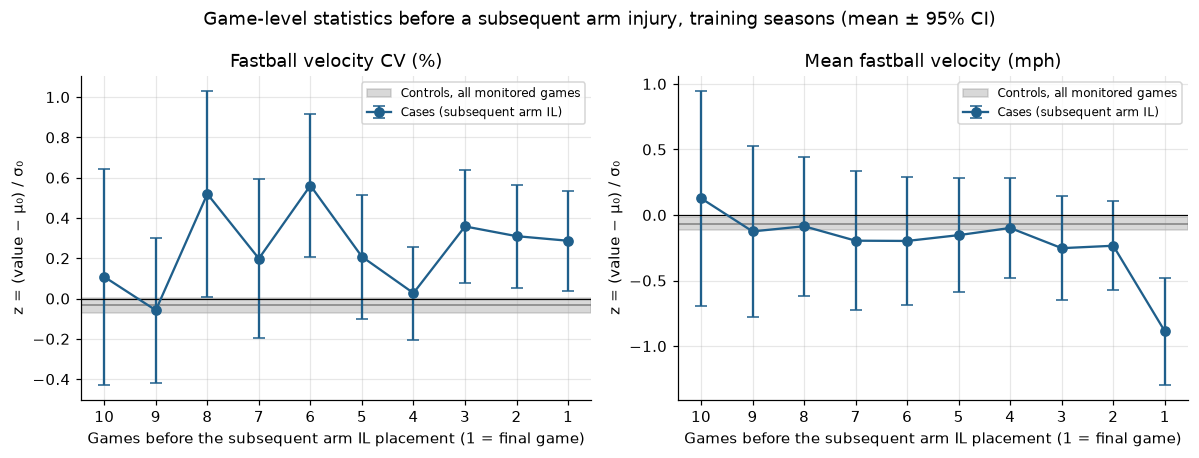

In [9]:
GAMES_BACK = 10
fig, axes = plt.subplots(1, len(METRICS), figsize=(5.5 * len(METRICS), 4.2), squeeze=False)
descriptive_rows = []
train_cases = [u for u in train_uids if units.at[u, "case"] == 1]
train_ctrls = [u for u in train_uids if units.at[u, "case"] == 0]
for ax, (m, spec) in zip(axes[0], METRICS.items()):
    ctrl = np.concatenate([unit_data[u]["z"][m] for u in train_ctrls] or [[]])
    case_rows = [{"games_before_IL": back, "z": value}
                 for u in train_cases
                 for back, value in enumerate(unit_data[u]["z"][m][::-1][:GAMES_BACK], start=1)]
    cz = pd.DataFrame(case_rows, columns=["games_before_IL", "z"])
    s = cz.groupby("games_before_IL")["z"].agg(["mean", "std", "count"]).reindex(range(1, GAMES_BACK + 1))
    s["half"] = 1.96 * s["std"] / np.sqrt(s["count"])
    if len(ctrl):
        c_mean, c_half = ctrl.mean(), 1.96 * ctrl.std(ddof=1) / np.sqrt(len(ctrl))
        ax.axhspan(c_mean - c_half, c_mean + c_half, color="grey", alpha=0.3, label="Controls, all monitored games")
        ax.axhline(c_mean, color="grey", lw=1)
    ax.errorbar(s.index, s["mean"], yerr=s["half"], fmt="o-", color="#1f5f8b", capsize=4,
                label="Cases (subsequent arm IL)")
    ax.axhline(0, color="black", lw=0.8)
    ax.invert_xaxis()
    ax.set_xticks(range(1, GAMES_BACK + 1))
    ax.set_xlabel("Games before the subsequent arm IL placement (1 = final game)")
    ax.set_ylabel("z = (value − μ₀) / σ₀")
    ax.set_title(spec["label"])
    ax.legend(fontsize=8)
    descriptive_rows.append(s.assign(statistic=m).reset_index())
fig.suptitle("Game-level statistics before a subsequent arm injury, training seasons (mean ± 95% CI)")
fig.tight_layout()
save(fig, "E1_statistics_before_subsequent_arm_IL")
pd.concat(descriptive_rows).to_csv(OUT_DIR / "descriptive_games_before_IL.csv", index=False)

## 8. The monitoring-length problem

A case's chart stops at his subsequent arm IL date; a control's runs to the end of the season (or to a
non-arm IL). If controls are watched for more games, they get more chances to signal by chance, and an
"any signal" comparison is biased against the chart. If the per-game false-alarm chance is $p$, the
chance of at least one alarm in $L$ games is $1-(1-p)^L$.

In [10]:
exposure = (units.loc[units["split"] == "train"]
                 .assign(group=lambda d: np.where(d["case"] == 1, "case", "control"))
                 .groupby(["group", "role"])["monitored_games"]
                 .describe()[["count", "25%", "50%", "75%", "mean"]])
exposure.to_csv(OUT_DIR / "monitored_games_by_group.csv")
display(exposure.round(1))

count  25%   50%   75%  mean
group   role                                  
case    mixed       8.0  5.0   7.0   9.2   7.8
        reliever   47.0  2.0   4.0   9.0   6.2
        starter    42.0  4.0   6.5   9.8   7.1
control mixed      10.0  5.8  10.0  17.2  11.5
        reliever  162.0  3.0   7.0  15.0  10.0
        starter   135.0  7.0  11.0  15.5  11.9

## 9. EWMA-CUSUM charts, matched on monitoring length (training seasons)

**Chart.** The same one-sided EWMA-CUSUM as the NBA study, checked below against its lower-sided formula.

**Matched evaluation.** A case's chart is read over his $m$ monitored games. Each control is read over
his **first $m$ monitored games since return** (controls with fewer than $m$ games are not used for that
case, as in the pitch-count matching of the replication notebook), and only controls in the **same role**
(starter / reliever / mixed) are used, because starters and relievers differ in games per season and in
how noisy their game statistics are. So both groups are judged on the same
exposure, at the same point after return.

* **Sensitivity**: share of cases whose chart signals at any of their $m$ games.
* **Matched specificity**: for each case, the share of eligible (same-length, same-role) controls that do **not** signal within
  their first $m$ games, averaged over cases (each case counts once).
* **Matched AUC** (threshold-free, for each λ): each case's chart peak against the eligible controls'
  peaks over their first $m$ games; the share of controls it beats (ties ½), averaged over cases. 0.5 =
  chance. 95% intervals resample **pitchers** (all of a pitcher's units together).

The unmatched ("any signal over the whole series") numbers are kept alongside for comparison.

In [11]:
def ewma_cusum(dev, lam):
    """One-sided EWMA-CUSUM on deviations signed toward the hypothesis (signal if path > h)."""
    path = np.empty(len(dev))
    prev = 0.0
    for j, x in enumerate(dev):
        prev = max(0.0, lam * x + (1 - lam) * prev)
        path[j] = prev
    return path


def nba_lower(values, mu0, sigma0, lam):
    """The NBA study's statistic, as written in its notebook (for the check below)."""
    stat, prev = [], 0.0
    for v in values:
        pci = (v - (mu0 - 2 * sigma0)) / sigma0
        prev = min(lam * (pci - 2) + (1 - lam) * prev, 0.0)
        stat.append(prev)
    return np.array(stat)


rng_check = np.random.default_rng(1)
vals = rng_check.normal(93, 1, 50)
for lam in (0.05, 0.45, 0.95):
    np.testing.assert_allclose(-nba_lower(vals, 93.2, 0.8, lam),
                               ewma_cusum(-(vals - 93.2) / 0.8, lam), atol=1e-12)
print("Chart matches the NBA study's lower-sided EWMA-CUSUM (sign-flipped).")


def peaks(uids, key, lam):
    """Running maximum of the chart for each unit: peaks[u][m-1] = highest value over the first m games."""
    return {u: np.maximum.accumulate(ewma_cusum(unit_data[u]["dev"][key], lam)) for u in uids}


def pair_matrices(uids, key, lam, role=None, P=None, labels=None):
    """S (case beats control), V (valid pair) for cases vs controls cut to the case's length.
    P: precomputed peaks (optional); labels: {uid: 0/1} overriding units['case'] (for permutations)."""
    lab = labels if labels is not None else {u: int(units.at[u, "case"]) for u in uids}
    cases = [u for u in uids if lab[u] == 1 and (role is None or units.at[u, "role"] == role)]
    ctrls = [u for u in uids if lab[u] == 0 and (role is None or units.at[u, "role"] == role)]
    if not cases or not ctrls:
        return cases, ctrls, None, None, None
    P = P if P is not None else peaks(cases + ctrls, key, lam)
    L = max(len(P[u]) for u in ctrls)
    C = np.full((len(ctrls), L), np.nan)
    for j, u in enumerate(ctrls):
        C[j, :len(P[u])] = P[u]
    case_peak = np.array([P[u][-1] for u in cases])
    case_len = np.array([len(P[u]) for u in cases])
    col = np.full((len(cases), len(ctrls)), np.nan)
    ok = case_len <= L
    col[ok] = C[:, case_len[ok] - 1].T                      # control peaks over the case's first m games
    V = ~np.isnan(col)
    if MATCH_WITHIN_ROLE:
        V &= (np.array([units.at[u, "role"] for u in cases])[:, None]
              == np.array([units.at[u, "role"] for u in ctrls])[None, :])
    S = np.where(V, (case_peak[:, None] > col) + 0.5 * (case_peak[:, None] == col), 0.0)
    return cases, ctrls, case_peak, col, (S, V)


def matched_grid(uids, key, lambdas, hs, role=None):
    hs = np.asarray(hs, float)
    rows = []
    for lam in lambdas:
        cases, ctrls, case_peak, col, SV = pair_matrices(uids, key, lam, role)
        if SV is None:
            continue
        V = SV[1]
        use = V.any(axis=1)
        for h in hs:
            sens = (case_peak[use] > h).mean()
            with np.errstate(invalid="ignore"):
                spec_i = np.nanmean(np.where(V, col <= h, np.nan), axis=1)
            rows.append({"chart": key, "lambda": lam, "h": h, "cases": int(use.sum()), "controls": len(ctrls),
                         "Sensitivity": sens, "Matched_specificity": np.nanmean(spec_i[use])})
    out = pd.DataFrame(rows)
    if len(out):
        out["Youden"] = out["Sensitivity"] + out["Matched_specificity"] - 1
    return out


def cluster_codes(cases, ctrls):
    ids = np.array([units.at[u, "pkey"] for u in cases + ctrls])
    groups, codes = np.unique(ids, return_inverse=True)
    return len(groups), codes[:len(cases)], codes[len(cases):]


def eq_auc(S, V, w_i, w_h):
    SV = S * V
    denom = V @ w_h
    with np.errstate(invalid="ignore", divide="ignore"):
        placement = (SV @ w_h) / denom
    ok = (denom > 0) & (w_i > 0)
    return np.sum(w_i[ok] * placement[ok]) / np.sum(w_i[ok]) if ok.any() else np.nan


def matched_auc(uids, key, lam, role=None, n_boot=None):
    cases, ctrls, _, _, SV = pair_matrices(uids, key, lam, role)
    if SV is None:
        return {"cases": len(cases), "controls": len(ctrls), "AUC": np.nan, "lower95": np.nan, "upper95": np.nan}
    S, V = SV
    n_groups, ci, hi = cluster_codes(cases, ctrls)
    est = eq_auc(S, V, np.ones(len(cases)), np.ones(len(ctrls)))
    rng = np.random.default_rng(SEED)
    draws = []
    for _ in range(n_boot or N_BOOT):
        t = np.bincount(rng.integers(n_groups, size=n_groups), minlength=n_groups).astype(float)
        draws.append(eq_auc(S, V, t[ci], t[hi]))
    lo, up = np.nanpercentile(draws, [2.5, 97.5])
    return {"cases": int(V.any(axis=1).sum()), "controls": len(ctrls), "AUC": est, "lower95": lo, "upper95": up}


auc_rows = []
for key in CHARTS:
    for lam in np.r_[LAMBDA_GRID_LOW, LAMBDA_GRID]:
        auc_rows.append({"chart": key, "lambda": lam, **matched_auc(train_uids, key, lam)})
train_auc = pd.DataFrame(auc_rows)
train_auc.to_csv(OUT_DIR / "train_matched_auc.csv", index=False)
print(f"Training units: {len(train_uids)} ({len(train_cases)} cases, {len(train_ctrls)} controls)")
print("Matched AUC by chart and λ (threshold-free; 0.5 = chance):")
display(train_auc.pivot(index="lambda", columns="chart", values="AUC").round(3))
display(train_auc.sort_values("AUC", ascending=False).groupby("chart").head(1).round(3))

Chart matches the NBA study's lower-sided EWMA-CUSUM (sign-flipped).
Training units: 404 (97 cases, 307 controls)
Matched AUC by chart and λ (threshold-free; 0.5 = chance):


chart,cv|per_fb,cv|pooled,velo|per_fb,velo|pooled
lambda,,,,
0.05,0.543,0.546,0.572,0.574
0.15,0.546,0.550,0.573,0.575
0.25,0.551,0.554,0.574,0.578
0.35,0.552,0.553,0.576,0.578
0.45,0.549,0.552,0.578,0.580
0.55,0.549,0.551,0.578,0.582
0.65,0.546,0.550,0.580,0.585
0.75,0.546,0.550,0.581,0.585
0.85,0.550,0.550,0.578,0.584


,chart,lambda,cases,controls,AUC,lower95,upper95
27,velo|pooled,0.75,97,307,0.585,0.519,0.657
37,velo|per_fb,0.75,97,307,0.581,0.514,0.652
2,cv|pooled,0.25,97,307,0.554,0.480,0.627
13,cv|per_fb,0.35,97,307,0.552,0.482,0.623


### Permutation test (the main significance test)

Case / control labels are shuffled **within season × role** (so each shuffle keeps the same number of
cases per season and role), and the matched AUC is recomputed at every λ. Each shuffle's **best** λ is
kept, so the test accounts for having picked the best λ. Shuffling also absorbs any small built-in tilt
of the matched comparison (on simulated data with no signal, the shuffled matched AUC for CV averaged
about 0.52 rather than 0.50). p = share of shuffles whose best AUC is at least the observed best.

Shuffling units assumes units are independent. A pitcher who appears in several seasons is not: if his
true level sits off the shrunk baseline, every one of his units looks the same way. The test is therefore
also run on **one unit per pitcher** (his earliest training season). If the two p-values disagree, trust
the one-unit-per-pitcher version.

In [12]:
ALL_LAMBDAS = np.r_[LAMBDA_GRID_LOW, LAMBDA_GRID]
true_labels = {u: int(units.at[u, "case"]) for u in train_uids}
# One unit per pitcher (his earliest training season): removes repeat pitchers, whose persistent
# offsets from the shrunk baseline make unit-level shuffling too optimistic.
first_unit = (units.loc[train_uids].sort_values("Season").groupby("pkey")["uid"].first().tolist())
n_repeat = int((units.loc[train_uids].groupby("pkey").size() > 1).sum())
print(f"Training pitchers with more than one unit: {n_repeat} "
      f"({len(train_uids)} units from {units.loc[train_uids, 'pkey'].nunique()} pitchers)")


def best_auc(P_by_lam, key, labels, uids):
    vals = []
    for lam in ALL_LAMBDAS:
        cases, ctrls, _, _, SV = pair_matrices(uids, key, lam, P=P_by_lam[lam], labels=labels)
        vals.append(eq_auc(SV[0], SV[1], np.ones(len(cases)), np.ones(len(ctrls))) if SV else np.nan)
    vals = np.array(vals, float)
    i = int(np.nanargmax(vals))
    return vals[i], ALL_LAMBDAS[i]


rng = np.random.default_rng(SEED)
perm_rows = []
for subset_name, subset in [("all units", train_uids), ("one unit per pitcher", first_unit)]:
  strata = units.loc[subset].groupby(["Season", "role"])["uid"].apply(list).tolist()
  for key in CHARTS:
    P_by_lam = {lam: peaks(subset, key, lam) for lam in ALL_LAMBDAS}
    observed, lam_best = best_auc(P_by_lam, key, true_labels, subset)
    null = []
    for _ in range(N_PERM):
        labels = {}
        for members in strata:
            labels.update(zip(members, rng.permutation([true_labels[u] for u in members])))
        null.append(best_auc(P_by_lam, key, labels, subset)[0])
    null = np.array(null)
    perm_rows.append({"units": subset_name, "n_units": len(subset),
                      "cases": int(sum(true_labels[u] for u in subset)),
                      "chart": key, "best_lambda": lam_best, "observed_best_AUC": observed,
                      "shuffled_best_AUC_mean": null.mean(), "shuffled_95th_pct": np.quantile(null, 0.95),
                      "p_value": (1 + (null >= observed).sum()) / (N_PERM + 1)})
perm_test = pd.DataFrame(perm_rows)
perm_test.to_csv(OUT_DIR / "train_permutation_test.csv", index=False)
display(perm_test.round(3))

Training pitchers with more than one unit: 64 (404 units from 327 pitchers)


,units,n_units,cases,chart,best_lambda,observed_best_AUC,shuffled_best_AUC_mean,shuffled_95th_pct,p_value
0,all units,404,97,cv|pooled,0.25,0.554,0.503,0.558,0.074
1,all units,404,97,cv|per_fb,0.35,0.552,0.498,0.554,0.060
2,all units,404,97,velo|pooled,0.75,0.585,0.543,0.597,0.092
3,all units,404,97,velo|per_fb,0.75,0.581,0.540,0.592,0.114
4,one unit per pitcher,327,77,cv|pooled,0.45,0.563,0.516,0.578,0.102
5,one unit per pitcher,327,77,cv|per_fb,0.35,0.562,0.511,0.568,0.084
6,one unit per pitcher,327,77,velo|pooled,0.65,0.617,0.545,0.605,0.028
7,one unit per pitcher,327,77,velo|per_fb,0.65,0.614,0.545,0.606,0.032


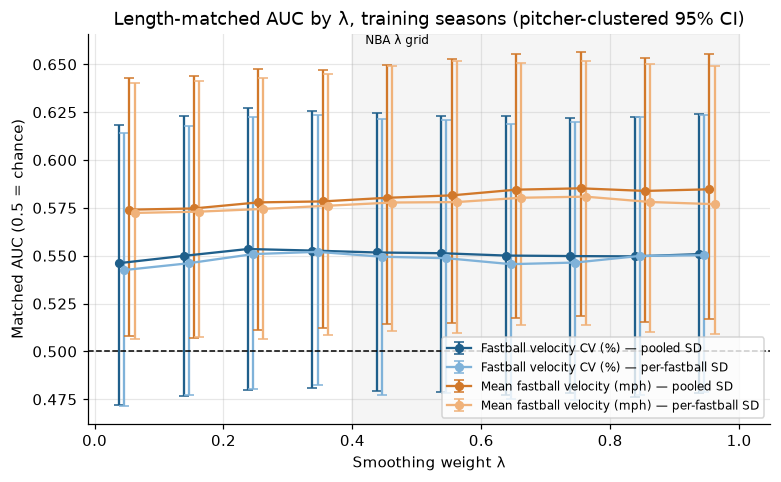

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.6))
colors = {"cv|pooled": "#1f5f8b", "cv|per_fb": "#7fb2d9", "velo|pooled": "#d1782a", "velo|per_fb": "#f0b27a"}
offsets = np.linspace(-0.012, 0.012, len(CHARTS))
for off, key in zip(offsets, CHARTS):
    d = train_auc.loc[train_auc["chart"] == key]
    ax.errorbar(d["lambda"] + off, d["AUC"], yerr=[d["AUC"] - d["lower95"], d["upper95"] - d["AUC"]],
                fmt="o-", capsize=3, ms=5, color=colors.get(key), label=CHARTS[key]["label"])
ax.axhline(0.5, ls="--", color="black", lw=1)
ax.axvspan(LAMBDA_GRID.min() - 0.05, LAMBDA_GRID.max() + 0.05, color="grey", alpha=0.08)
ax.text(LAMBDA_GRID.min() - 0.03, ax.get_ylim()[1], "NBA λ grid", va="top", fontsize=8)
ax.set_xlabel("Smoothing weight λ")
ax.set_ylabel("Matched AUC (0.5 = chance)")
ax.set_title("Length-matched AUC by λ, training seasons (pitcher-clustered 95% CI)")
ax.legend(fontsize=8)
save(fig, "E2_matched_auc_by_lambda")

### Matched sensitivity / specificity across (λ, h) and the selected setting

The h grid now runs from 0.05 to 5 (the NBA grid stops at 0.50, which on game-level velocity lets a single
ordinary bad game trip the chart). Selection: highest **matched Youden** on the training seasons (ties:
higher sensitivity, then larger h). The best point within the NBA grid (h ≤ 0.50) is shown for reference,
with the unmatched numbers at the same settings.

In [15]:
train_grid = pd.concat([matched_grid(train_uids, key, LAMBDA_GRID, H_GRID_WIDE) for key in CHARTS],
                       ignore_index=True)
train_grid.to_csv(OUT_DIR / "train_matched_grid.csv", index=False)


def unmatched(uids, key, lam, h):
    """Any signal over the whole monitored series (the original evaluation)."""
    sig = np.array([ewma_cusum(unit_data[u]["dev"][key], lam).max() > h for u in uids])
    case = np.array([units.at[u, "case"] == 1 for u in uids])
    return {"unmatched_sens": sig[case].mean() if case.any() else np.nan,
            "unmatched_spec": (~sig[~case]).mean() if (~case).any() else np.nan}


def pick(grid):
    ranked = grid.dropna(subset=["Youden"]).sort_values(["chart", "Youden", "Sensitivity", "h"],
                                                         ascending=[True, False, False, False])
    return ranked.groupby("chart").head(1).set_index("chart")


chosen = pick(train_grid)
nba_best = pick(train_grid.loc[train_grid["h"] <= H_GRID_NBA.max() + 1e-9])
summary_rows = []
for label, table in [("selected (wide h)", chosen), ("best within NBA grid", nba_best)]:
    for key, r in table.iterrows():
        summary_rows.append({"setting": label, "chart": key, "lambda": r["lambda"], "h": r["h"],
                             "Sensitivity": r["Sensitivity"], "Matched_specificity": r["Matched_specificity"],
                             "Youden": r["Youden"], **unmatched(train_uids, key, r["lambda"], r["h"])})
selection_table = pd.DataFrame(summary_rows)
selection_table.to_csv(OUT_DIR / "train_selected_settings.csv", index=False)
display(selection_table.round(3))
for key, r in chosen.iterrows():
    if r["h"] in (H_GRID_WIDE.min(), H_GRID_WIDE.max()) or r["lambda"] in (LAMBDA_GRID.min(), LAMBDA_GRID.max()):
        print(f"Note: {key} selection (λ = {r['lambda']:.2f}, h = {r['h']:.2f}) is on the edge of the grid.")

,setting,chart,lambda,h,Sensitivity,Matched_specificity,Youden,unmatched_sens,unmatched_spec
0,selected (wide h),cv|per_fb,0.95,2.00,0.299,0.804,0.103,0.299,0.743
1,selected (wide h),cv|pooled,0.75,1.75,0.278,0.843,0.121,0.278,0.762
2,selected (wide h),velo|per_fb,0.85,1.75,0.381,0.761,0.143,0.381,0.687
3,selected (wide h),velo|pooled,0.65,2.50,0.196,0.943,0.139,0.196,0.896
4,best within NBA grid,cv|per_fb,0.45,0.50,0.557,0.521,0.077,0.557,0.430
5,best within NBA grid,cv|pooled,0.45,0.50,0.557,0.514,0.071,0.557,0.423
6,best within NBA grid,velo|per_fb,0.65,0.45,0.701,0.411,0.112,0.701,0.316
7,best within NBA grid,velo|pooled,0.75,0.50,0.701,0.408,0.109,0.701,0.316


Note: cv|per_fb selection (λ = 0.95, h = 2.00) is on the edge of the grid.


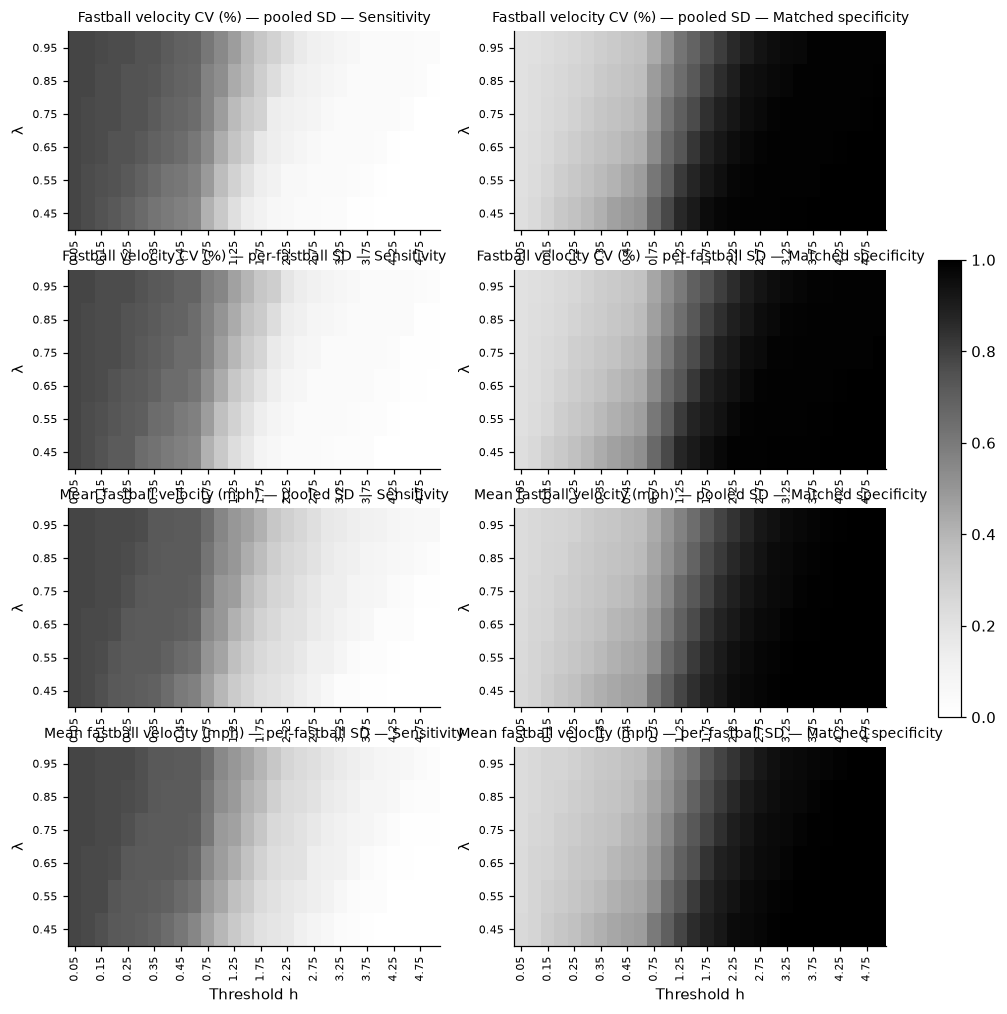

In [16]:
fig, axes = plt.subplots(len(CHARTS), 2, figsize=(12, 2.7 * len(CHARTS)), squeeze=False)
for row, key in enumerate(CHARTS):
    for col, measure in enumerate(["Sensitivity", "Matched_specificity"]):
        ax = axes[row, col]
        grid = train_grid.loc[train_grid["chart"] == key].pivot(index="lambda", columns="h", values=measure)
        im = ax.imshow(grid.to_numpy(float), cmap="Greys", vmin=0, vmax=1, aspect="auto", origin="lower")
        ax.set_xticks(range(0, len(grid.columns), 2), [f"{h:.2f}" for h in grid.columns[::2]], rotation=90, fontsize=7)
        ax.set_yticks(range(len(grid.index)), [f"{l:.2f}" for l in grid.index], fontsize=7)
        ax.grid(False)
        ax.set_title(f"{CHARTS[key]['label']} — {measure.replace('_', ' ')}", fontsize=9)
        ax.set_ylabel("λ")
        if row == len(CHARTS) - 1:
            ax.set_xlabel("Threshold h")
fig.colorbar(im, ax=axes, shrink=0.5)
save(fig, "E3_matched_grid_heatmaps")

### Block-bootstrap false-alarm check (matched exposure)

Synthetic in-control sequences are built from training units' own baseline games (standardized with the
frozen baseline, resampled in overlapping blocks of 3), each as long as a randomly chosen training
**case's** monitored series, so the exposure matches the matched specificity above. If the observed
matched false-positive rate (1 − matched specificity) is at or below the bootstrap rate, controls are not
alarming more often than chance on in-control data would explain.

In [17]:
rng = np.random.default_rng(SEED)
case_lengths = units.loc[(units["split"] == "train") & (units["case"] == 1), "monitored_games"].to_numpy()
null_rows = []
for key in CHARTS:
    pools = [unit_data[u]["baseline_dev"][key] for u in train_uids
             if len(unit_data[u]["baseline_dev"][key]) >= BLOCK_LEN]
    if not pools or not len(case_lengths):
        continue
    starts = [(i, s) for i, p in enumerate(pools) for s in range(len(p) - BLOCK_LEN + 1)]
    seqs = []
    for L in rng.choice(case_lengths, size=N_NULL_SEQUENCES):
        idx = rng.integers(len(starts), size=-(-int(L) // BLOCK_LEN))
        seqs.append(np.concatenate([pools[starts[j][0]][starts[j][1]:starts[j][1] + BLOCK_LEN] for j in idx])[:L])
    for lam in LAMBDA_GRID:
        pk = np.array([ewma_cusum(s, lam).max() for s in seqs])
        for h in H_GRID_WIDE:
            null_rows.append({"chart": key, "lambda": lam, "h": h, "bootstrap_false_alarm": (pk > h).mean()})
null_check = train_grid.merge(pd.DataFrame(null_rows), on=["chart", "lambda", "h"])
null_check["observed_false_positive_rate"] = 1 - null_check["Matched_specificity"]
null_check["at_or_below_bootstrap"] = null_check["observed_false_positive_rate"] <= null_check["bootstrap_false_alarm"] + 1e-12
null_check.to_csv(OUT_DIR / "block_bootstrap_false_alarm.csv", index=False)
display(null_check.groupby("chart")["at_or_below_bootstrap"].mean().rename("share of grid at or below bootstrap").round(3))
display(null_check.merge(chosen.reset_index()[["chart", "lambda", "h"]], on=["chart", "lambda", "h"])
                  [["chart", "lambda", "h", "observed_false_positive_rate", "bootstrap_false_alarm"]].round(3))

chart
cv|per_fb      0.726
cv|pooled      0.643
velo|per_fb    0.381
velo|pooled    0.387
Name: share of grid at or below bootstrap, dtype: float64

,chart,lambda,h,observed_false_positive_rate,bootstrap_false_alarm
0,cv|pooled,0.75,1.75,0.157,0.118
1,cv|per_fb,0.95,2.00,0.196,0.145
2,velo|pooled,0.65,2.50,0.057,0.017
3,velo|per_fb,0.85,1.75,0.239,0.140


### ROC frontier (matched, training seasons)

As in the NBA study: the Pareto frontier of the (λ, h) grid, anchored at (0, 0) and (1, 1), with the
trapezoidal area under it. Because the frontier picks the best (λ, h) at every false-positive rate, its
AUC is optimistic; the threshold-free matched AUC above is the fairer single number.

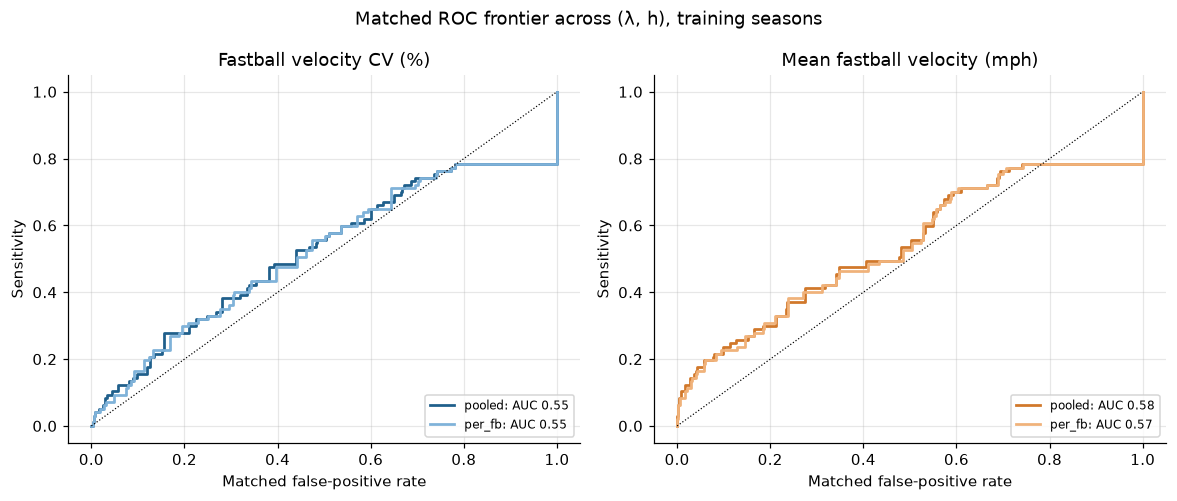

,chart,frontier_AUC
0,cv|pooled,0.550
1,cv|per_fb,0.550
2,velo|pooled,0.578
3,velo|per_fb,0.575


In [18]:
def roc_frontier(sens, fpr):
    pts = np.vstack([[0, 0], np.column_stack([fpr, sens]), [1, 1]])
    pts = pts[~np.isnan(pts).any(axis=1)]
    pts = pts[np.lexsort((-pts[:, 1], pts[:, 0]))]
    frontier, best = [], -1.0
    for x, y in pts:
        if y > best:
            frontier.append((x, y))
            best = y
    frontier = np.array(frontier)
    if frontier[-1, 0] < 1:
        frontier = np.vstack([frontier, [1, best]])
    area = np.trapezoid(frontier[:, 1], frontier[:, 0]) if hasattr(np, "trapezoid") else np.trapz(frontier[:, 1], frontier[:, 0])
    return frontier, area


fig, axes = plt.subplots(1, len(METRICS), figsize=(5.4 * len(METRICS), 4.6), squeeze=False)
roc_rows = []
for ax, m in zip(axes[0], METRICS):
    for key in [k for k in CHARTS if CHARTS[k]["stat"] == m]:
        g = train_grid.loc[train_grid["chart"] == key]
        frontier, area = roc_frontier(g["Sensitivity"].to_numpy(), 1 - g["Matched_specificity"].to_numpy())
        ax.step(frontier[:, 0], frontier[:, 1], where="post", lw=1.8, color=colors.get(key),
                label=f"{CHARTS[key]['mode']}: AUC {area:.2f}")
        roc_rows.append({"chart": key, "frontier_AUC": area})
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.set_xlabel("Matched false-positive rate")
    ax.set_ylabel("Sensitivity")
    ax.set_title(METRICS[m]["label"])
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Matched ROC frontier across (λ, h), training seasons")
fig.tight_layout()
save(fig, "E4_matched_roc")
pd.DataFrame(roc_rows).to_csv(OUT_DIR / "train_matched_roc_auc.csv", index=False)
display(pd.DataFrame(roc_rows).round(3))

## 10. Per-game analysis: does an alarm mean an arm IL is near?

The matched comparison asks "does this pitcher's chart ever signal?". The per-game view asks the question
a team would face each day: **when the chart is in alarm after a game, is an arm IL placement more
likely within the next `HAZARD_K` appearances?** Every monitored game of every training unit is one row:

* **alarm** = chart above h after that game (selected λ, h for each chart),
* **outcome** = the unit is a case and this game is one of his last `HAZARD_K` appearances before the
  subsequent arm IL date.

Reported: the outcome rate after alarm games and after no-alarm games, their ratio (crude risk ratio),
and the **role-adjusted** (Mantel-Haenszel, stratified by starter / reliever / mixed) risk ratio, which is
the one to read: starters have fewer post-return games, so a larger share of their games fall in the
outcome window, and any role difference in alarm rates would otherwise show up as a false association.
Intervals resample pitchers.

In [19]:
def game_rows(uids, key, lam, h):
    out = []
    for u in uids:
        d = unit_data[u]
        path = ewma_cusum(d["dev"][key], lam)
        back = d["n_apps_before_stop"] - d["monitored"]["app_index"].to_numpy()    # 1 = final appearance
        case = units.at[u, "case"] == 1
        out.append(pd.DataFrame({"uid": u, "pkey": units.at[u, "pkey"], "role": units.at[u, "role"],
                                 "case": int(case), "games_before_stop": back, "alarm": path > h,
                                 "outcome": case & (back <= HAZARD_K)}))
    return pd.concat(out, ignore_index=True)


def risk_ratio(df):
    a = df.loc[df["alarm"], "outcome"]
    b = df.loc[~df["alarm"], "outcome"]
    ra, rb = (a.mean() if len(a) else np.nan), (b.mean() if len(b) else np.nan)
    return ra, rb, (ra / rb if rb and rb > 0 else np.nan)


ROLES = ["starter", "reliever", "mixed", "unknown"]


def _rr_from_tab(tab, w):
    """tab[g, r] = (alarm games, games, alarm & outcome, no-alarm & outcome) for pitcher g in role r."""
    T = np.einsum("g,grk->rk", w, tab)                 # weighted totals per role
    a_n, n, ao, no = T.sum(axis=0)
    pa = ao / a_n if a_n else np.nan
    pb = no / (n - a_n) if n - a_n else np.nan
    crude = pa / pb if pb and pb > 0 else np.nan
    with np.errstate(invalid="ignore", divide="ignore"):
        num = np.nansum(np.where(T[:, 1] > 0, T[:, 2] * (T[:, 1] - T[:, 0]) / T[:, 1], 0))
        den = np.nansum(np.where(T[:, 1] > 0, T[:, 3] * T[:, 0] / T[:, 1], 0))
    mh = num / den if den > 0 else np.nan
    return pa, pb, crude, mh


def risk_ratio_ci(df):
    """Crude and role-adjusted (Mantel-Haenszel) risk ratios; pitcher-clustered interval for the MH ratio."""
    groups = df["pkey"].unique()
    gi = {g: i for i, g in enumerate(groups)}
    tab = np.zeros((len(groups), len(ROLES), 4))
    for (g, r), x in df.groupby(["pkey", "role"]):
        tab[gi[g], ROLES.index(r)] += [x["alarm"].sum(), len(x), (x["alarm"] & x["outcome"]).sum(),
                                       (~x["alarm"] & x["outcome"]).sum()]
    pa, pb, crude, mh = _rr_from_tab(tab, np.ones(len(groups)))
    rng = np.random.default_rng(SEED)
    draws = [_rr_from_tab(tab, np.bincount(rng.integers(len(groups), size=len(groups)),
                                           minlength=len(groups)).astype(float))[3] for _ in range(N_BOOT)]
    draws = np.array(draws, float)
    lo, up = np.nanpercentile(draws, [2.5, 97.5]) if np.isfinite(draws).any() else (np.nan, np.nan)
    return {"p_alarm": pa, "p_no_alarm": pb, "RR_crude": crude, "RR_role_adjusted": mh,
            "RR_adj_lower95": lo, "RR_adj_upper95": up}


hazard_rows, per_game_tables = [], {}
for key, r in chosen.iterrows():
    df = game_rows(train_uids, key, r["lambda"], r["h"])
    per_game_tables[key] = df
    rr = risk_ratio_ci(df)
    hazard_rows.append({"chart": key, "lambda": r["lambda"], "h": r["h"], "games": len(df),
                        "alarm_games": int(df["alarm"].sum()), "outcome_games": int(df["outcome"].sum()),
                        f"P(arm IL within {HAZARD_K} | alarm)": rr["p_alarm"],
                        f"P(arm IL within {HAZARD_K} | no alarm)": rr["p_no_alarm"],
                        **{k: v for k, v in rr.items() if k.startswith("RR")}})
hazard = pd.DataFrame(hazard_rows)
hazard.to_csv(OUT_DIR / "per_game_alarm_risk_ratio.csv", index=False)
display(hazard.round(3))

,chart,lambda,h,games,alarm_games,outcome_games,P(arm IL within 3 | alarm),P(arm IL within 3 | no alarm),RR_crude,RR_role_adjusted,RR_adj_lower95,RR_adj_upper95
0,cv|per_fb,0.95,2.00,3988,190,195,0.089,0.047,1.909,1.936,1.075,2.947
1,cv|pooled,0.75,1.75,3988,194,195,0.088,0.047,1.868,1.872,0.978,2.938
2,velo|per_fb,0.85,1.75,3988,444,195,0.104,0.042,2.464,2.540,1.640,3.765
3,velo|pooled,0.65,2.50,3988,118,195,0.195,0.044,4.386,4.456,2.479,6.919


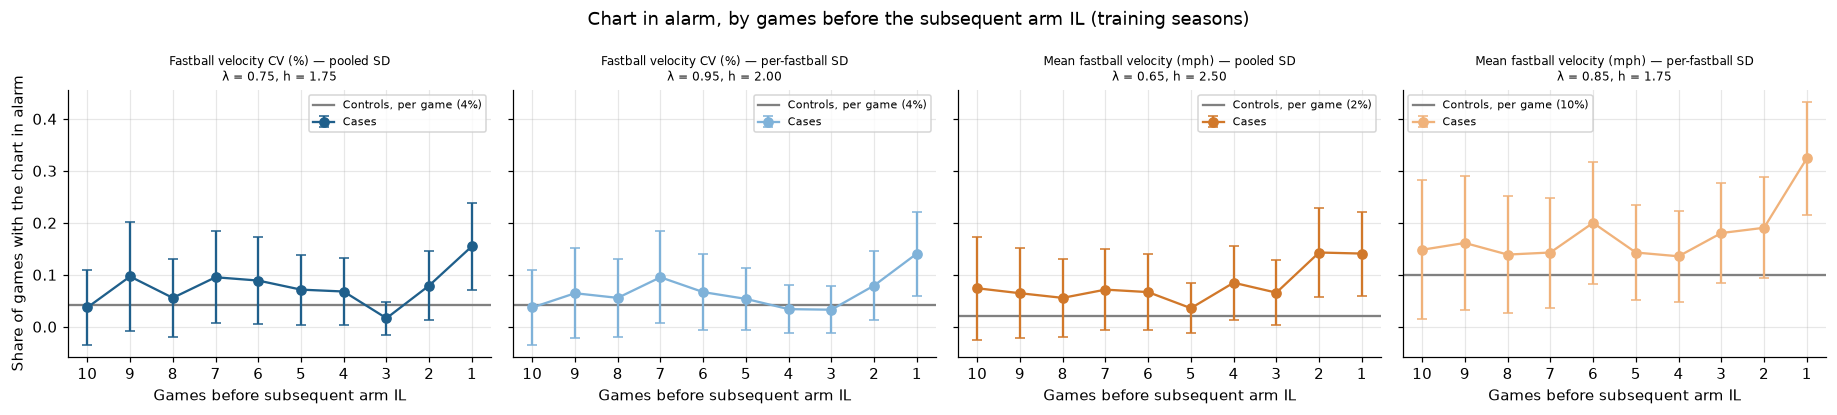

In [20]:
fig, axes = plt.subplots(1, len(CHARTS), figsize=(4.2 * len(CHARTS), 3.8), sharey=True, squeeze=False)
for ax, key in zip(axes[0], CHARTS):
    df = per_game_tables[key]
    cases = df.loc[df["case"] == 1]
    rate = cases.loc[cases["games_before_stop"] <= GAMES_BACK].groupby("games_before_stop")["alarm"].agg(["mean", "count"])
    rate = rate.reindex(range(1, GAMES_BACK + 1))
    half = 1.96 * np.sqrt(rate["mean"] * (1 - rate["mean"]) / rate["count"])
    ctrl_rate = df.loc[df["case"] == 0, "alarm"].mean()
    ax.axhline(ctrl_rate, color="grey", lw=1.5, label=f"Controls, per game ({ctrl_rate:.0%})")
    ax.errorbar(rate.index, rate["mean"], yerr=half, fmt="o-", capsize=3, color=colors.get(key), label="Cases")
    ax.invert_xaxis()
    ax.set_xticks(range(1, GAMES_BACK + 1))
    ax.set_xlabel("Games before subsequent arm IL")
    ax.set_title(f"{CHARTS[key]['label']}\nλ = {chosen.loc[key, 'lambda']:.2f}, h = {chosen.loc[key, 'h']:.2f}", fontsize=8)
    ax.legend(fontsize=7)
axes[0, 0].set_ylabel("Share of games with the chart in alarm")
fig.suptitle("Chart in alarm, by games before the subsequent arm IL (training seasons)")
fig.tight_layout()
save(fig, "E5_alarm_rate_by_games_before_IL")

### Honest training estimates: leave-one-season-out

The selected (λ, h) and the numbers above are scored on the same seasons used to pick them, out of
several hundred (chart, λ, h) combinations, so they are optimistic (on simulated data with **no** signal,
the in-sample risk ratio at a selected setting can come out well above 1). Here each training season is
left out in turn: (λ, h) is picked on the other training seasons by matched Youden and scored on the
left-out season (cases matched with controls from that season). The pooled results are the honest
training estimates; the threshold-free matched AUC in Section 9 involves no selection.

In [21]:
loso_rows, loso_games, loso_picks = [], [], []
for key in CHARTS:
    hits, specs, frames = [], [], []
    for season in TRAIN_SEASONS:
        fit_u = [u for u in train_uids if units.at[u, "Season"] != season]
        ev_u = [u for u in train_uids if units.at[u, "Season"] == season]
        grid = matched_grid(fit_u, key, LAMBDA_GRID, H_GRID_WIDE)
        if grid.empty:
            continue
        r = pick(grid).loc[key]
        loso_picks.append({"chart": key, "left_out": season, "lambda": r["lambda"], "h": r["h"]})
        cases, ctrls, case_peak, col, SV = pair_matrices(ev_u, key, r["lambda"])
        if SV is None:
            continue
        V = SV[1]
        use = V.any(axis=1)
        hits += list(case_peak[use] > r["h"])
        with np.errstate(invalid="ignore"):
            specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])
        frames.append(game_rows(ev_u, key, r["lambda"], r["h"]))
    games = pd.concat(frames, ignore_index=True)
    rr = risk_ratio_ci(games)
    loso_rows.append({"chart": key, "cases": len(hits), "Sensitivity": np.mean(hits),
                      "Matched_specificity": np.mean(specs), "Youden": np.mean(hits) + np.mean(specs) - 1,
                      **{k: v for k, v in rr.items() if k.startswith("RR")}})
loso = pd.DataFrame(loso_rows)
loso.to_csv(OUT_DIR / "train_leave_one_season_out.csv", index=False)
pd.DataFrame(loso_picks).to_csv(OUT_DIR / "train_leave_one_season_out_picks.csv", index=False)
print("Leave-one-season-out (honest) training estimates:")
display(loso.round(3))
print("Settings picked in each fold (stable picks are reassuring):")
display(pd.DataFrame(loso_picks).pivot(index="left_out", columns="chart", values=["lambda", "h"]))

/tmp/ipykernel_12721/3102297555.py:19: RuntimeWarning: Mean of empty slice
  specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])
/tmp/ipykernel_12721/3102297555.py:19: RuntimeWarning: Mean of empty slice
  specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])
/tmp/ipykernel_12721/3102297555.py:19: RuntimeWarning: Mean of empty slice
  specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])
/tmp/ipykernel_12721/3102297555.py:19: RuntimeWarning: Mean of empty slice
  specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])
/tmp/ipykernel_12721/3102297555.py:19: RuntimeWarning: Mean of empty slice
  specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])
/tmp/ipykernel_12721/3102297555.py:19: RuntimeWarning: Mean of empty slice
  specs += list(np.nanmean(np.where(V, col <= r["h"], np.nan), axis=1)[use])
/tmp/ipykernel_12721/3102297555.py:19: RuntimeWarning: Mean of empty slice
  specs += li

Leave-one-season-out (honest) training estimates:


,chart,cases,Sensitivity,Matched_specificity,Youden,RR_crude,RR_role_adjusted,RR_adj_lower95,RR_adj_upper95
0,cv|pooled,93,0.280,0.801,0.081,1.669,1.613,0.914,2.371
1,cv|per_fb,93,0.344,0.710,0.055,1.708,1.657,0.993,2.489
2,velo|pooled,93,0.247,0.795,0.043,1.446,1.538,0.838,2.418
3,velo|per_fb,93,0.376,0.695,0.072,1.846,1.962,1.259,2.882


Settings picked in each fold (stable picks are reassuring):


lambda                                           h            \
chart    cv|per_fb cv|pooled velo|per_fb velo|pooled cv|per_fb cv|pooled   
left_out                                                                   
2021          0.85      0.75        0.65        0.45      1.75      1.75   
2022          0.95      0.75        0.85        0.85      2.00      1.75   
2023          0.85      0.75        0.85        0.55      1.75      1.75   
2024          0.95      0.75        0.85        0.95      1.00      1.75   
2025          0.95      0.55        0.65        0.65      1.50      0.75   

                                  
chart    velo|per_fb velo|pooled  
left_out                          
2021            0.45        0.35  
2022            1.75        2.50  
2023            1.75        2.25  
2024            1.75        2.75  
2025            2.50        2.75

## 11. Starters and relievers separately

Matched AUC within each role (cases and controls of the same role only) at each chart's selected λ, and
the selected setting's matched sensitivity / specificity. Role comes from the year before the initial
injury: share of games started ≥ 0.6 → starter, ≤ 0.2 → reliever, otherwise mixed.

In [22]:
role_rows = []
for key, r in chosen.iterrows():
    for role in ["starter", "reliever", "mixed"]:
        a = matched_auc(train_uids, key, r["lambda"], role=role)
        g = matched_grid(train_uids, key, [r["lambda"]], [r["h"]], role=role)
        role_rows.append({"chart": key, "role": role, "lambda": r["lambda"], "h": r["h"], **a,
                          "Sensitivity": g["Sensitivity"].iat[0] if len(g) else np.nan,
                          "Matched_specificity": g["Matched_specificity"].iat[0] if len(g) else np.nan})
by_role = pd.DataFrame(role_rows)
by_role.to_csv(OUT_DIR / "train_by_role.csv", index=False)
display(by_role.round(3))

,chart,role,lambda,h,cases,controls,AUC,lower95,upper95,Sensitivity,Matched_specificity
0,cv|per_fb,starter,0.95,2.00,42,135,0.655,0.556,0.747,0.452,0.842
1,cv|per_fb,reliever,0.95,2.00,47,162,0.442,0.342,0.536,0.149,0.798
2,cv|per_fb,mixed,0.95,2.00,8,10,0.636,0.288,0.938,0.375,0.642
3,cv|pooled,starter,0.75,1.75,42,135,0.655,0.559,0.746,0.429,0.859
4,cv|pooled,reliever,0.75,1.75,47,162,0.441,0.342,0.532,0.128,0.840
5,cv|pooled,mixed,0.75,1.75,8,10,0.636,0.288,0.938,0.375,0.775
6,velo|per_fb,starter,0.85,1.75,42,135,0.569,0.467,0.678,0.381,0.751
7,velo|per_fb,reliever,0.85,1.75,47,162,0.568,0.466,0.673,0.362,0.767
8,velo|per_fb,mixed,0.85,1.75,8,10,0.687,0.373,0.950,0.500,0.779
9,velo|pooled,starter,0.65,2.50,42,135,0.580,0.473,0.689,0.286,0.927


## 12. Example control charts (training seasons)

For each chart at its selected (λ, h): one case whose chart signalled and the control with the median
peak. **Top:** game value with $\mu_0$ and $\mu_0 \pm 2\sigma$ ($\sigma$ varies by game in the per-fastball
version). **Bottom:** the EWMA-CUSUM with h; orange = subsequent arm IL.

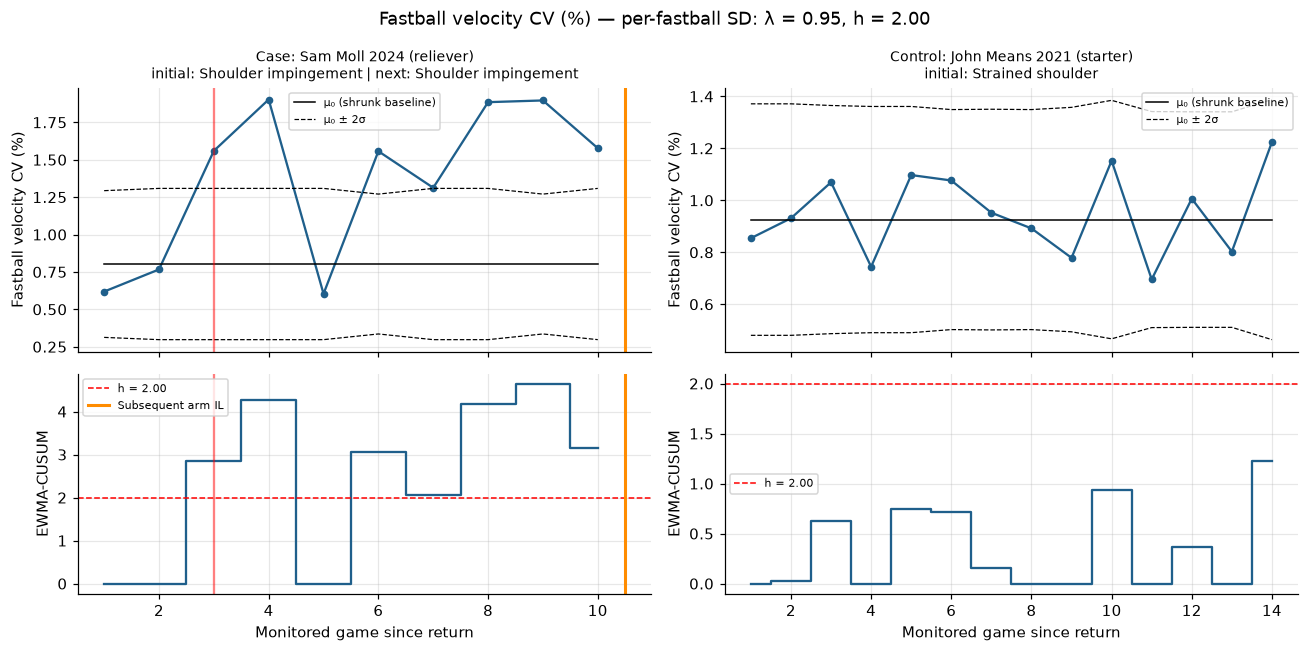

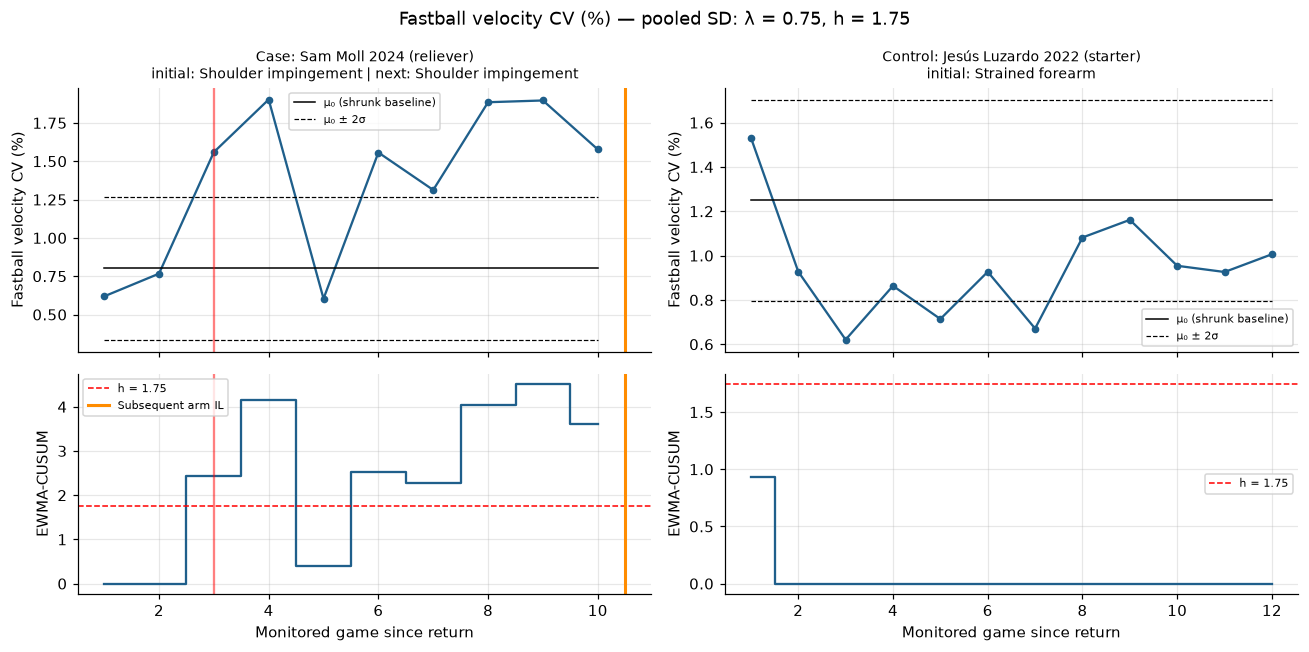

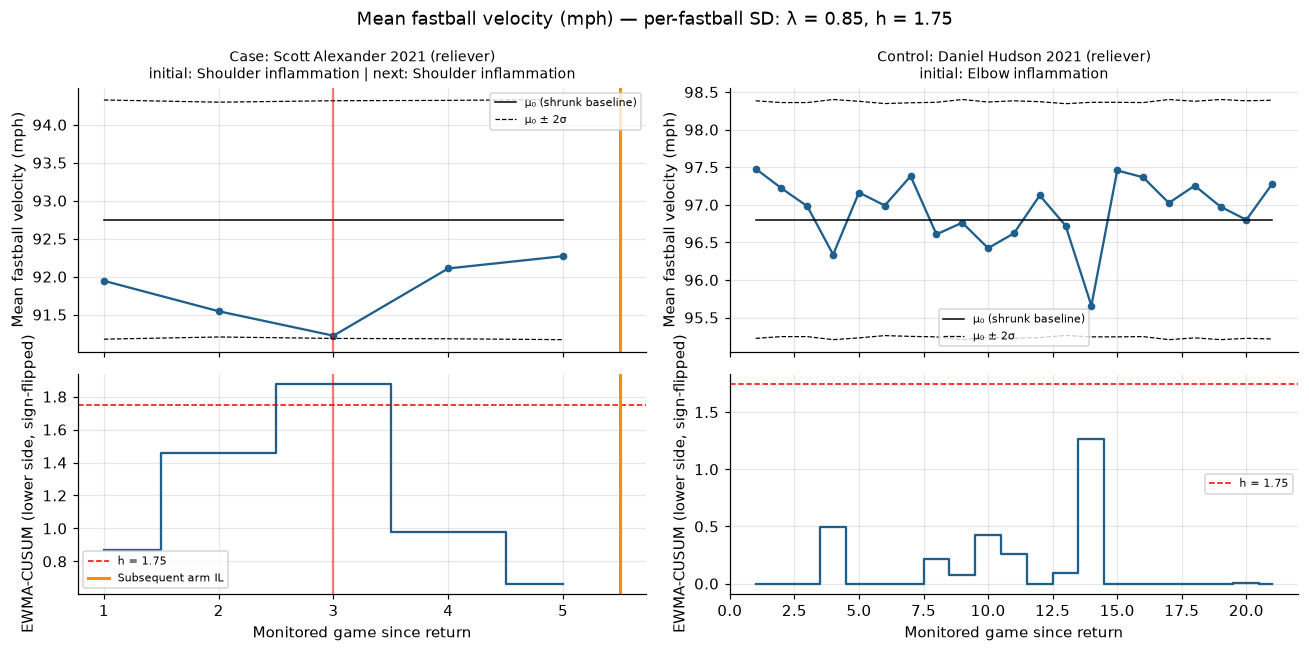

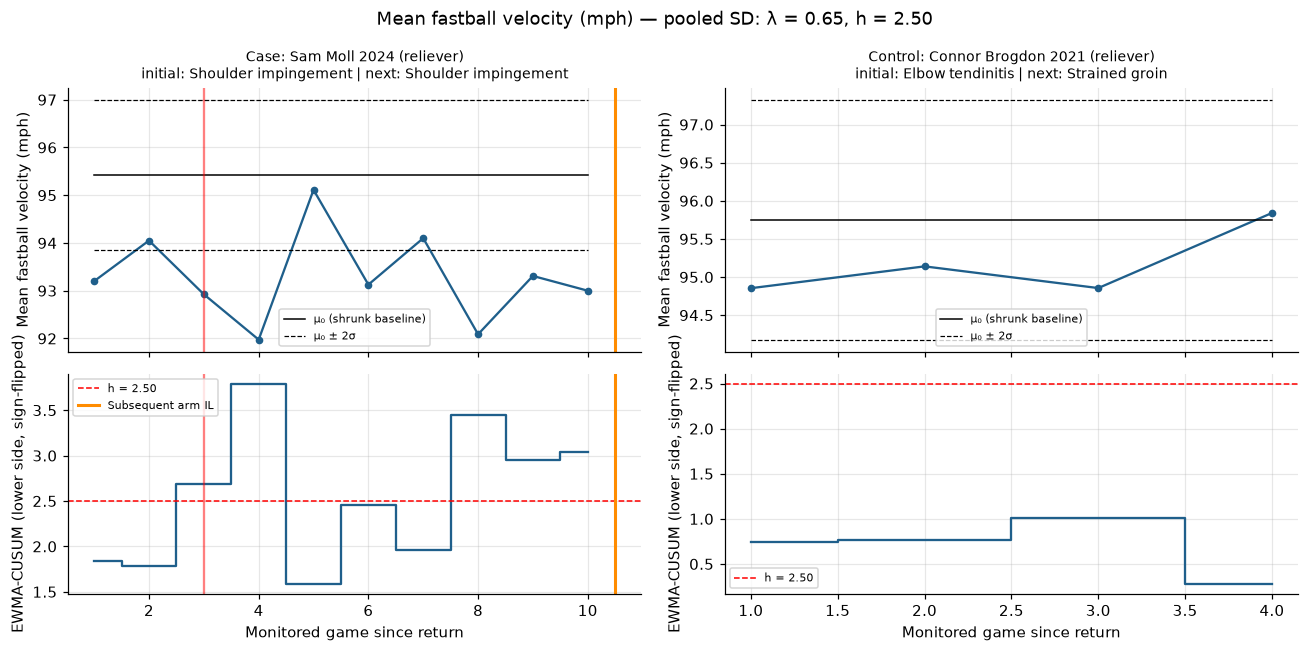

In [23]:
for key, r in chosen.iterrows():
    lam, h, m = r["lambda"], r["h"], CHARTS[key]["stat"]
    signalled = [u for u in train_cases if ewma_cusum(unit_data[u]["dev"][key], lam).max() > h]
    case_uid = signalled[0] if signalled else (train_cases[0] if train_cases else None)
    pk = {u: ewma_cusum(unit_data[u]["dev"][key], lam).max() for u in train_ctrls}
    ctrl_uid = min(pk, key=lambda u: abs(pk[u] - np.median(list(pk.values())))) if pk else None
    examples = [u for u in (case_uid, ctrl_uid) if u is not None]
    if not examples:
        continue
    fig, axes = plt.subplots(2, len(examples), figsize=(6 * len(examples), 6), sharex="col", squeeze=False,
                             gridspec_kw={"height_ratios": [1.2, 1]})
    for col, u in enumerate(examples):
        d, row = unit_data[u], units.loc[u]
        mon = d["monitored"]
        x = np.arange(1, len(mon) + 1)
        top, bot = axes[0, col], axes[1, col]
        mu0, sig = d["mu0"][m], d["sigma"][key]
        top.plot(x, mon[m], "o-", color="#1f5f8b", ms=4)
        top.plot(x, np.full(len(x), mu0), color="black", lw=1, label="μ₀ (shrunk baseline)")
        top.plot(x, mu0 + 2 * sig, color="black", ls="--", lw=0.8, label="μ₀ ± 2σ")
        top.plot(x, mu0 - 2 * sig, color="black", ls="--", lw=0.8)
        path = ewma_cusum(d["dev"][key], lam)
        bot.step(x, path, where="mid", color="#1f5f8b")
        bot.axhline(h, color="red", ls="--", lw=1, label=f"h = {h:.2f}")
        over = np.flatnonzero(path > h)
        if len(over):
            for axis in (top, bot):
                axis.axvline(over[0] + 1, color="red", alpha=0.5)
        if row["case"]:
            for axis in (top, bot):
                axis.axvline(len(x) + 0.5, color="darkorange", lw=2, label="Subsequent arm IL" if axis is bot else None)
        kind = "Case" if row["case"] else "Control"
        top.set_title(f"{kind}: {row['Name']} {row['Season']} ({row['role']})\ninitial: {row['initial_injury']}"
                      + (f" | next: {row['next_injury']}" if isinstance(row["next_injury"], str) else ""), fontsize=9)
        top.set_ylabel(METRICS[m]["label"])
        bot.set_ylabel("EWMA-CUSUM" + (" (lower side, sign-flipped)" if METRICS[m]["side"] == "lower" else ""))
        bot.set_xlabel("Monitored game since return")
        top.legend(fontsize=7)
        bot.legend(fontsize=7)
    fig.suptitle(f"{CHARTS[key]['label']}: λ = {lam:.2f}, h = {h:.2f}")
    fig.tight_layout()
    save(fig, f"E6_example_chart_{key.replace('|', '_')}")

## 13. Velocity and CV by games since return: cases vs controls

Section 7 lines cases up by games **before** the subsequent IL. A pattern there (e.g. coming back above
baseline and fading) could simply be what every pitcher does after a return, lined up differently. Here
both groups are lined up by games **since return**. If controls show the same shape, it is a return
effect, not a warning sign. Training seasons; z uses the pooled SD; n per point is shown underneath.

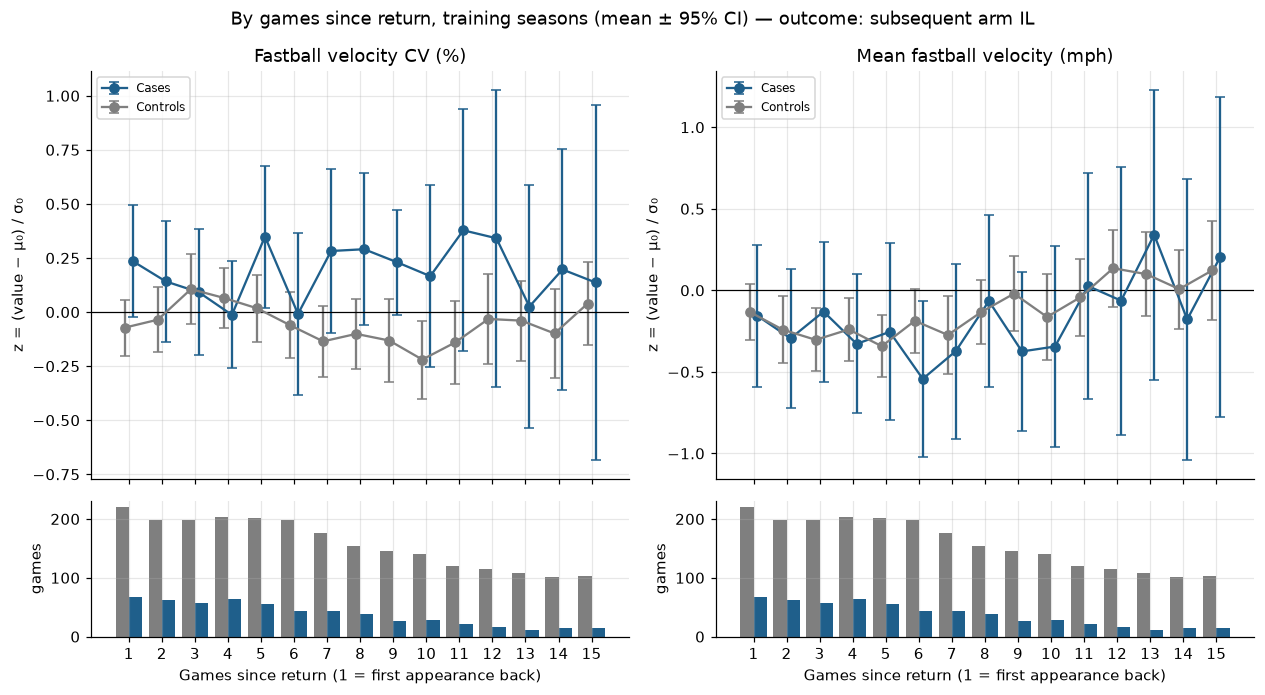

In [24]:
GAMES_SINCE = 15
fig, axes = plt.subplots(2, len(METRICS), figsize=(5.8 * len(METRICS), 6.4), squeeze=False, sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})
since_rows = []
for col, (m, spec) in enumerate(METRICS.items()):
    ax, axn = axes[0, col], axes[1, col]
    for label, group, color in [("Cases", train_cases, "#1f5f8b"), ("Controls", train_ctrls, "#7f7f7f")]:
        rows = [{"games_since_return": int(a) + 1, "z": z}
                for u in group
                for a, z in zip(unit_data[u]["monitored"]["app_index"], unit_data[u]["z"][m])]
        s = (pd.DataFrame(rows, columns=["games_since_return", "z"])
               .groupby("games_since_return")["z"].agg(["mean", "std", "count"])
               .reindex(range(1, GAMES_SINCE + 1)))
        half = 1.96 * s["std"] / np.sqrt(s["count"])
        ax.errorbar(s.index + (0.12 if label == "Cases" else -0.12), s["mean"], yerr=half, fmt="o-",
                    capsize=3, color=color, label=label)
        axn.bar(s.index + (0.2 if label == "Cases" else -0.2), s["count"], width=0.4, color=color)
        since_rows.append(s.assign(group=label, statistic=m).reset_index())
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylabel("z = (value − μ₀) / σ₀")
    ax.set_title(spec["label"])
    ax.legend(fontsize=8)
    axn.set_ylabel("games")
    axn.set_xlabel("Games since return (1 = first appearance back)")
    axn.set_xticks(range(1, GAMES_SINCE + 1))
fig.suptitle(f"By games since return, training seasons (mean ± 95% CI) — outcome: subsequent {OUTCOME_LABEL} IL")
fig.tight_layout()
save(fig, "E7_by_games_since_return")
pd.concat(since_rows).to_csv(OUT_DIR / "descriptive_games_since_return.csv", index=False)

## 14. Per-game model: how does velocity relate to the chance of a subsequent IL?

The control charts assume one direction (lower velocity → more risk). This model lets the data show the
shape. The two velocity terms add up to this game's velocity minus his baseline, split into "where he has been"
and "today's departure from it", so they do not compete for the same information. The first monitored
game back has no recent level and is left out. One row per monitored game (training seasons); the outcome is a subsequent IL placement within the
next `HAZARD_K` appearances. Logistic regression with **pitcher-clustered (sandwich) standard errors**.

**Prespecified primary model** (about 8 parameters, so roughly 10 outcome games per parameter are needed;
the cell prints the actual number):

| Term | Meaning |
|---|---|
| **Recent level**: mean velocity of his previous ≤5 post-return games minus his pre-injury baseline (mph), restricted cubic spline, 3 knots | Where he has been throwing; the spline allows a U-shape (high = more load, low = symptom) |
| **This game's change**: this game's mean velocity minus that recent level (mph) | A drop or rise today, relative to his own post-return level |
| log(pitches in the game) | Workload in that game |
| Days since his previous appearance (capped at 10) | Rest |
| Starter (vs not) | Role |
| log(1 + games since return) | Time since return |

Reported: odds ratios with 95% CIs, a Wald test for **non-linearity** of the level term (is there a
U-shape?), the partial effect of velocity level, and two simpler models: the true discrete-time hazard
(`K = 1`, the IL comes right after this game) with fewer terms, and the same model with CV in place of
velocity (CV per pooled SD). Odds ratios here are effect sizes to report with their intervals, not pass/fail tests.

In [27]:
import math


def chi2_sf(x, df):
    """Upper tail of chi-square for df = 1 or 2 (all that is needed here)."""
    if df == 1:
        return math.erfc(math.sqrt(max(x, 0) / 2))
    if df == 2:
        return math.exp(-max(x, 0) / 2)
    raise ValueError("df must be 1 or 2")


def rcs_basis(x, knots):
    """Restricted cubic spline (Harrell), 3 knots: returns [x, nonlinear term]."""
    t1, t2, t3 = knots
    p = lambda v: np.clip(v, 0, None) ** 3
    nl = (p(x - t1) - p(x - t2) * (t3 - t1) / (t3 - t2) + p(x - t3) * (t2 - t1) / (t3 - t2)) / (t3 - t1) ** 2
    return np.column_stack([x, nl])


def fit_logit(X, y, groups, ridge=1e-6, max_iter=100):
    """Logistic regression by Newton-Raphson, with a cluster-robust (sandwich) covariance."""
    beta = np.zeros(X.shape[1])
    beta[0] = np.log(max(y.mean(), 1e-6) / max(1 - y.mean(), 1e-6))
    pen = ridge * np.eye(X.shape[1]); pen[0, 0] = 0
    converged = False
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-(X @ beta)))
        W = p * (1 - p)
        H = X.T @ (X * W[:, None]) + pen
        step = np.linalg.solve(H, X.T @ (y - p) - pen @ beta)
        beta += step
        if np.max(np.abs(step)) < 1e-8:
            converged = True
            break
    p = 1 / (1 + np.exp(-(X @ beta)))
    H = X.T @ (X * (p * (1 - p))[:, None]) + pen
    Hinv = np.linalg.inv(H)
    scores = pd.DataFrame(X * (y - p)[:, None]).groupby(groups).sum().to_numpy()
    G = scores.shape[0]
    V = Hinv @ (scores.T @ scores) @ Hinv * G / max(G - 1, 1)
    return beta, V, converged


def per_game_frame(uids, k):
    rows = []
    for u in uids:
        d = unit_data[u]
        mon = d["monitored"]
        velo = mon["velo"].to_numpy(float)
        prior = mon["velo"].shift(1).rolling(5, min_periods=1).mean().to_numpy(float)
        back = d["n_apps_before_stop"] - mon["app_index"].to_numpy()
        rows.append(pd.DataFrame({
            "uid": u, "pkey": units.at[u, "pkey"], "case": int(units.at[u, "case"]),
            "velo_dev": prior - d["mu0"]["velo"],          # recent level (previous <=5 games) vs baseline
            "velo_change": velo - prior,                    # this game vs his recent level
            "cv_z": (mon["cv"].to_numpy(float) - d["mu0"]["cv"]) / fit_for(u, "cv")["sigma_w"],
            "log_pitches": np.log(mon["n_pitches"].to_numpy(float)),
            "rest_days": np.minimum(mon["rest_days"].to_numpy(float), REST_CAP),
            "starter": float(units.at[u, "role"] == "starter"),
            "log_games_since": np.log1p(mon["app_index"].to_numpy(float)),
            "outcome": ((units.at[u, "case"] == 1) & (back <= k)).astype(float)}))
    return pd.concat(rows, ignore_index=True).dropna()


TERM_LABELS = {"velo_dev": "recent level vs baseline (mph)", "velo_change": "this game vs recent level (mph)",
               "cv_z": "CV vs baseline (per SD)", "log_pitches": "log pitches in game",
               "rest_days": "days of rest (capped)", "starter": "starter", "log_games_since": "log(1 + games since return)"}


def model_table(df, terms, knots=None, label=""):
    cols, names = [np.ones(len(df))], ["intercept"]
    for t in terms:
        if t == "velo_dev_rcs":
            B = rcs_basis(df["velo_dev"].to_numpy(), knots)
            cols += [B[:, 0], B[:, 1]]
            names += ["recent level vs baseline (mph)", "recent level nonlinear"]
        else:
            cols.append(df[t].to_numpy(float))
            names.append(TERM_LABELS.get(t, t))
    X = np.column_stack(cols)
    y = df["outcome"].to_numpy(float)
    beta, V, ok = fit_logit(X, y, df["pkey"].to_numpy())
    se = np.sqrt(np.diag(V))
    tab = pd.DataFrame({"model": label, "term": names, "beta": beta, "se": se,
                        "OR": np.exp(beta), "OR_lower95": np.exp(beta - 1.96 * se),
                        "OR_upper95": np.exp(beta + 1.96 * se)})
    tab["p_value"] = [chi2_sf((b / s) ** 2, 1) if s > 0 else np.nan for b, s in zip(beta, se)]
    info = {"model": label, "games": len(df), "outcome_games": int(y.sum()),
            "outcome_units": int(df.loc[df["outcome"] == 1, "uid"].nunique()),
            "pitchers": df["pkey"].nunique(), "parameters": len(beta),
            "outcome_games_per_parameter": y.sum() / len(beta), "converged": ok}
    return tab, info, beta, V, names


train_games = per_game_frame(train_uids, HAZARD_K)
knots = np.quantile(train_games["velo_dev"], [0.10, 0.50, 0.90])
primary_terms = ["velo_dev_rcs", "velo_change", "log_pitches", "rest_days", "starter", "log_games_since"]
primary, primary_info, b_p, V_p, names_p = model_table(train_games, primary_terms, knots,
                                                       f"primary (K = {HAZARD_K})")

# Wald tests on the velocity-level term
i_lin, i_nl = names_p.index("recent level vs baseline (mph)"), names_p.index("recent level nonlinear")
wald_nl = b_p[i_nl] ** 2 / V_p[i_nl, i_nl]
idx = [i_lin, i_nl]
wald_level = float(b_p[idx] @ np.linalg.solve(V_p[np.ix_(idx, idx)], b_p[idx]))
tests = pd.DataFrame([
    {"test": "velocity level: any effect (2 df)", "chi2": wald_level, "p_value": chi2_sf(wald_level, 2)},
    {"test": "velocity level: non-linearity, e.g. U-shape (1 df)", "chi2": wald_nl, "p_value": chi2_sf(wald_nl, 1)},
])

hazard_games = per_game_frame(train_uids, 1)
k1, k1_info, *_ = model_table(hazard_games, ["velo_dev", "velo_change", "starter"], label="hazard (K = 1), 3 terms")
cvm, cv_info, *_ = model_table(train_games, ["cv_z", "log_pitches", "rest_days", "starter", "log_games_since"],
                               label=f"CV in place of velocity (K = {HAZARD_K})")

model_info = pd.DataFrame([primary_info, k1_info, cv_info])
model_terms = pd.concat([primary, k1, cvm], ignore_index=True)
model_info.to_csv(OUT_DIR / "per_game_model_info.csv", index=False)
model_terms.to_csv(OUT_DIR / "per_game_model_terms.csv", index=False)
tests.to_csv(OUT_DIR / "per_game_model_wald_tests.csv", index=False)
display(model_info.round(2))
if primary_info["outcome_games_per_parameter"] < 10:
    print("Note: fewer than 10 outcome games per parameter in the primary model; read its intervals as rough.")
display(model_terms.loc[model_terms["term"] != "intercept"].round(3))
display(tests.round(4))
print(f"Spline knots for velocity vs baseline (mph): {np.round(knots, 2)}")

,model,games,outcome_games,outcome_units,pitchers,parameters,outcome_games_per_parameter,converged
0,primary (K = 3),3584,178,79,302,8,22.25,True
1,"hazard (K = 1), 3 terms",3584,63,63,302,4,15.75,True
2,CV in place of velocity (K = 3),3584,178,79,302,6,29.67,True


,model,term,beta,se,OR,OR_lower95,OR_upper95,p_value
1,primary (K = 3),recent level vs baseline (mph),-0.642,0.222,0.526,0.340,0.813,0.004
2,primary (K = 3),recent level nonlinear,0.731,0.280,2.078,1.200,3.598,0.009
3,primary (K = 3),this game vs recent level (mph),-0.425,0.118,0.654,0.519,0.824,0.000
4,primary (K = 3),log pitches in game,0.120,0.245,1.127,0.697,1.823,0.625
5,primary (K = 3),days of rest (capped),0.017,0.043,1.017,0.936,1.106,0.684
6,primary (K = 3),starter,-0.099,0.406,0.906,0.409,2.008,0.808
7,primary (K = 3),log(1 + games since return),-0.213,0.125,0.808,0.633,1.033,0.089
9,"hazard (K = 1), 3 terms",recent level vs baseline (mph),-0.220,0.145,0.803,0.604,1.068,0.131
10,"hazard (K = 1), 3 terms",this game vs recent level (mph),-0.772,0.187,0.462,0.321,0.667,0.000
11,"hazard (K = 1), 3 terms",starter,0.155,0.261,1.168,0.700,1.949,0.552


,test,chi2,p_value
0,velocity level: any effect (2 df),8.3952,0.015
1,"velocity level: non-linearity, e.g. U-shape (1...",6.8234,0.009


Spline knots for velocity vs baseline (mph): [-1.3  -0.08  1.3 ]


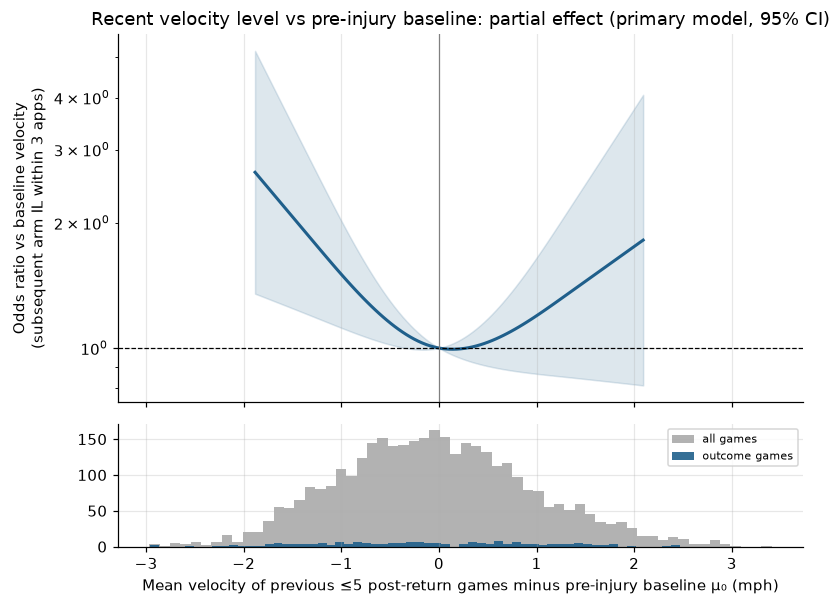

In [26]:
# Partial effect of velocity level (vs his pre-injury baseline), other terms held fixed.
grid = np.linspace(*np.quantile(train_games["velo_dev"], [0.02, 0.98]), 101)
B = rcs_basis(grid, knots) - rcs_basis(np.array([0.0]), knots)
log_or = B @ b_p[[i_lin, i_nl]]
se = np.sqrt(np.einsum("ij,jk,ik->i", B, V_p[np.ix_(idx, idx)], B))
fig, (ax, axh) = plt.subplots(2, 1, figsize=(7.5, 5.6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax.plot(grid, np.exp(log_or), color="#1f5f8b", lw=2)
ax.fill_between(grid, np.exp(log_or - 1.96 * se), np.exp(log_or + 1.96 * se), color="#1f5f8b", alpha=0.15)
ax.axhline(1, color="black", lw=0.8, ls="--")
ax.axvline(0, color="grey", lw=0.8)
ax.set_yscale("log")
ax.set_ylabel(f"Odds ratio vs baseline velocity\n(subsequent {OUTCOME_LABEL} IL within {HAZARD_K} apps)")
ax.set_title("Recent velocity level vs pre-injury baseline: partial effect (primary model, 95% CI)")
axh.hist(train_games["velo_dev"], bins=60, color="grey", alpha=0.6, label="all games")
axh.hist(train_games.loc[train_games["outcome"] == 1, "velo_dev"], bins=60, color="#1f5f8b", alpha=0.9,
         label="outcome games")
axh.set_xlabel("Mean velocity of previous ≤5 post-return games minus pre-injury baseline μ₀ (mph)")
axh.legend(fontsize=7)
fig.tight_layout()
save(fig, "E8_velocity_partial_effect")

In [28]:
# ---- Section 14 follow-up: hockey-stick, velocity + CV, and lead time (training seasons) ----
# Run after the Section 14 cells (uses model_table, TERM_LABELS, fit_for, unit_data, units, train_uids).

def fit_logit(X, y, groups, ridge=1e-4, max_iter=200):
    """Logistic regression (Newton with step-halving and a tiny ridge, so near-separation cannot crash it),
    with a pitcher-clustered sandwich covariance. Replaces the Section 14 version for the models below."""
    beta = np.zeros(X.shape[1])
    beta[0] = np.log(max(y.mean(), 1e-6) / max(1 - y.mean(), 1e-6))
    pen = ridge * np.eye(X.shape[1]); pen[0, 0] = 0
    nll = lambda b: np.sum(np.logaddexp(0, X @ b) - y * (X @ b)) + 0.5 * b @ pen @ b
    converged = False
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-(X @ beta)))
        H = X.T @ (X * (p * (1 - p))[:, None]) + pen
        step = np.linalg.lstsq(H, X.T @ (y - p) - pen @ beta, rcond=None)[0]
        t, f0 = 1.0, nll(beta)
        while nll(beta + t * step) > f0 + 1e-10 and t > 1e-8:
            t /= 2
        beta = beta + t * step
        if np.max(np.abs(t * step)) < 1e-8:
            converged = True
            break
    p = 1 / (1 + np.exp(-(X @ beta)))
    Hinv = np.linalg.pinv(X.T @ (X * (p * (1 - p))[:, None]) + pen)
    scores = pd.DataFrame(X * (y - p)[:, None]).groupby(groups).sum().to_numpy()
    G = scores.shape[0]
    V = Hinv @ (scores.T @ scores) @ Hinv * G / max(G - 1, 1)
    if np.max(np.abs(beta[1:])) > 10:
        print("  Warning: a coefficient above 10 in absolute value; the outcome may be (nearly) separable.")
    return beta, V, converged


def per_game_frame_back(uids):
    """One row per monitored game, with the outcome-independent predictors and `back`
    (appearances until the stop date; 1 = his final appearance before it)."""
    rows = []
    for u in uids:
        d = unit_data[u]
        mon = d["monitored"]
        velo = mon["velo"].to_numpy(float)
        prior = mon["velo"].shift(1).rolling(5, min_periods=1).mean().to_numpy(float)
        rows.append(pd.DataFrame({
            "uid": u, "pkey": units.at[u, "pkey"], "case": int(units.at[u, "case"]),
            "back": d["n_apps_before_stop"] - mon["app_index"].to_numpy(),
            "velo_dev": prior - d["mu0"]["velo"],                 # recent level vs baseline (mph)
            "velo_change": velo - prior,                           # this game vs recent level (mph)
            "cv_z": (mon["cv"].to_numpy(float) - d["mu0"]["cv"]) / fit_for(u, "cv")["sigma_w"],
            "log_pitches": np.log(mon["n_pitches"].to_numpy(float)),
            "rest_days": np.minimum(mon["rest_days"].to_numpy(float), REST_CAP),
            "starter": float(units.at[u, "role"] == "starter"),
            "log_games_since": np.log1p(mon["app_index"].to_numpy(float))}))
    df = pd.concat(rows, ignore_index=True).dropna()               # drops each unit's first game back
    df["below_baseline"] = np.clip(-df["velo_dev"], 0, None)       # mph below baseline (0 if at/above)
    df["above_baseline"] = np.clip(df["velo_dev"], 0, None)        # mph above baseline (0 if at/below)
    return df


TERM_LABELS.update({"below_baseline": "recent level: mph BELOW baseline",
                    "above_baseline": "recent level: mph ABOVE baseline"})

base = per_game_frame_back(train_uids)
covariates = ["log_pitches", "rest_days", "starter", "log_games_since"]

# Outcome A (as in the primary model): subsequent arm IL within the next HAZARD_K appearances.
std = base.assign(outcome=((base["case"] == 1) & (base["back"] <= HAZARD_K)).astype(float))
# Outcome B (lead time): IL 2..HAZARD_K appearances ahead; each case's final game is dropped,
# so nothing here can come from the injury game itself.
lead = (base.loc[~((base["case"] == 1) & (base["back"] == 1))]
            .assign(outcome=lambda d: ((d["case"] == 1) & d["back"].between(2, HAZARD_K)).astype(float)))

specs = [
    ("1. hockey-stick", std, ["below_baseline", "velo_change"] + covariates),
    ("2. hockey-stick + above-baseline arm", std, ["below_baseline", "above_baseline", "velo_change"] + covariates),
    ("3. velocity + CV", std, ["below_baseline", "velo_change", "cv_z"] + covariates),
    ("4. lead time: velocity + CV, final game dropped", lead, ["below_baseline", "velo_change", "cv_z"] + covariates),
    ("5. lead time: velocity only, final game dropped", lead, ["below_baseline", "velo_change"] + covariates),
]
follow_terms, follow_info = [], []
for label, df, terms in specs:
    tab, info, *_ = model_table(df, terms, label=label)
    follow_terms.append(tab)
    follow_info.append(info)
follow_terms = pd.concat(follow_terms, ignore_index=True)
follow_info = pd.DataFrame(follow_info)
follow_terms.to_csv(OUT_DIR / "per_game_followup_terms.csv", index=False)
follow_info.to_csv(OUT_DIR / "per_game_followup_info.csv", index=False)

display(follow_info[["model", "games", "outcome_games", "outcome_units", "pitchers",
                     "parameters", "outcome_games_per_parameter", "converged"]].round(2))
key = ["recent level: mph BELOW baseline", "recent level: mph ABOVE baseline",
       "this game vs recent level (mph)", "CV vs baseline (per SD)"]
display(follow_terms.loc[follow_terms["term"].isin(key),
                         ["model", "term", "OR", "OR_lower95", "OR_upper95", "p_value"]].round(3))
print("Covariates (pitches, rest, starter, games since return) are in per_game_followup_terms.csv.")
print("How to read: OR per mph BELOW baseline > 1 = sustained shortfall raises risk; "
      "OR per mph for 'this game vs recent level' < 1 = a drop today raises risk; "
      "OR per SD of CV > 1 = more inconsistent games raise risk. "
      "Models 4-5 exclude the injury game, so any effect there is lead time, not detection.")

,model,games,outcome_games,outcome_units,pitchers,parameters,outcome_games_per_parameter,converged
0,1. hockey-stick,3584,178,79,302,7,25.43,True
1,2. hockey-stick + above-baseline arm,3584,178,79,302,8,22.25,True
2,3. velocity + CV,3584,178,79,302,8,22.25,True
3,"4. lead time: velocity + CV, final game dropped",3521,115,69,298,8,14.38,True
4,"5. lead time: velocity only, final game dropped",3521,115,69,298,7,16.43,True


,model,term,OR,OR_lower95,OR_upper95,p_value
1,1. hockey-stick,recent level: mph BELOW baseline,1.524,1.047,2.219,0.028
2,1. hockey-stick,this game vs recent level (mph),0.642,0.512,0.804,0.000
8,2. hockey-stick + above-baseline arm,recent level: mph BELOW baseline,1.780,1.201,2.637,0.004
9,2. hockey-stick + above-baseline arm,recent level: mph ABOVE baseline,1.413,0.923,2.162,0.111
10,2. hockey-stick + above-baseline arm,this game vs recent level (mph),0.654,0.520,0.824,0.000
16,3. velocity + CV,recent level: mph BELOW baseline,1.430,0.987,2.071,0.058
17,3. velocity + CV,this game vs recent level (mph),0.672,0.534,0.847,0.001
18,3. velocity + CV,CV vs baseline (per SD),1.212,1.050,1.401,0.009
24,"4. lead time: velocity + CV, final game dropped",recent level: mph BELOW baseline,1.310,0.872,1.967,0.193
25,"4. lead time: velocity + CV, final game dropped",this game vs recent level (mph),0.826,0.639,1.067,0.144


Covariates (pitches, rest, starter, games since return) are in per_game_followup_terms.csv.
How to read: OR per mph BELOW baseline > 1 = sustained shortfall raises risk; OR per mph for 'this game vs recent level' < 1 = a drop today raises risk; OR per SD of CV > 1 = more inconsistent games raise risk. Models 4-5 exclude the injury game, so any effect there is lead time, not detection.


Leave-one-season-out, training seasons [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]. Every configuration is calibrated so 5% of control games alarm; λ picked on the other seasons.


,config,parameters,control games in alarm,case games 2-3 before IL in alarm,lead RR (role-adjusted),lead RR lower95,lead RR upper95,final game in alarm (detection),early-warning sensitivity (unit),matched specificity (unit)
0,velocity only,1,0.050,0.129,2.695,1.390,4.445,0.183,0.169,0.902
1,CV only,1,0.057,0.097,1.596,0.720,3.107,0.127,0.135,0.894
2,log CV only,1,0.061,0.097,1.443,0.649,2.871,0.169,0.157,0.897
3,Option 1: velocity + CV,2,0.055,0.137,2.630,1.351,4.751,0.197,0.180,0.943
4,Option 1: velocity + log CV,2,0.054,0.137,2.561,1.309,4.483,0.211,0.191,0.929
5,"Option 2: max(velocity, CV)",1,0.055,0.105,2.021,0.909,3.601,0.211,0.180,0.886
6,"Option 2: max(velocity, log CV)",1,0.055,0.137,2.636,1.357,4.440,0.197,0.202,0.863


λ picked in each fold (stable picks are reassuring):


config,CV only,Option 1: velocity + CV,Option 1: velocity + log CV,"Option 2: max(velocity, CV)","Option 2: max(velocity, log CV)",log CV only,velocity only
left_out,,,,,,,
2021,0.25,0.35,0.35,0.75,0.85,0.15,0.55
2022,0.25,0.35,0.35,0.25,0.65,0.25,0.65
2023,0.35,0.35,0.35,0.65,0.65,0.35,0.35
2024,0.15,0.35,0.35,0.45,0.35,0.15,0.35
2025,0.25,0.35,0.35,0.35,0.45,0.75,0.35


Settings frozen on all training seasons (for the held-out season):


,config,kind,stat_1,stat_2,lambda_1,lambda_2,h_1,h_2,train_early_warning_hit_rate
0,velocity only,single,velo,NaN,0.65,NaN,2.008,NaN,0.145
1,CV only,single,cv,NaN,0.15,NaN,0.757,NaN,0.113
2,log CV only,single,logcv,NaN,0.15,NaN,0.752,NaN,0.097
3,Option 1: velocity + CV,two,velo,cv,0.35,0.05,2.029,0.549,0.145
4,Option 1: velocity + log CV,two,velo,logcv,0.35,0.25,2.028,1.151,0.153
5,"Option 2: max(velocity, CV)",max,velo,cv,0.75,NaN,2.317,NaN,0.145
6,"Option 2: max(velocity, log CV)",max,velo,logcv,0.65,NaN,2.097,NaN,0.145


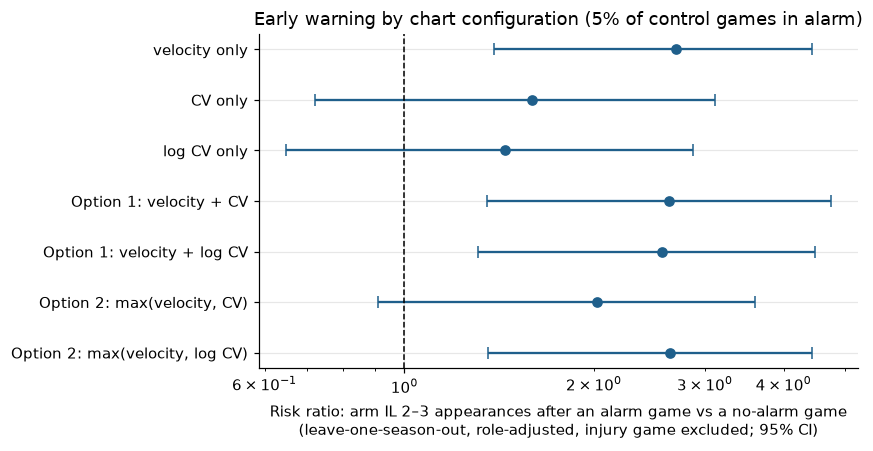

In [33]:
# ==== Step 3: two charts (Option 1) vs one combined chart (Option 2), training seasons ====
# Paste after the Section 14 follow-up cell. Uses objects already in memory: units, unit_data, train_uids,
# fit_shrinkage, shrunk_mean, ewma_cusum, risk_ratio_ci, HAZARD_K, MIN_UNITS_ROLE_FIT, SEED, OUT_DIR, save.
#
# Configurations (each calibrated so that ALARM_RATE of control games are in alarm):
#   single charts : velocity (lower-sided) | CV (upper) | log CV (upper)           -> 1 parameter (λ)
#   Option 1      : velocity chart + CV chart, alarm if either fires               -> 2 parameters (λ_v, λ_cv)
#   Option 2      : one chart on max(velocity chart, CV chart), shared λ and h     -> 1 parameter (λ)
# Each chart is the same EWMA-CUSUM as before, on z = (x - μ0)/σ0 with the role-shrunk baseline.
# λ is chosen to maximise early-warning hits on the training folds; results are leave-one-season-out.

ALARM_RATE = 0.05
LAMS = np.round(np.arange(0.05, 0.951, 0.10), 2)
K_LEAD = HAZARD_K

# ---- log(CV) baseline (same role-shrunk Approach B as the other statistics) ----
for u in units["uid"]:
    d = unit_data[u]
    for frame in (d["baseline"], d["monitored"]):
        cv = pd.to_numeric(frame["cv"], errors="coerce").to_numpy(dtype=np.float64)
        frame["logcv"] = np.log(np.clip(cv, 1e-6, None))
_logcv_all = fit_shrinkage([unit_data[u]["baseline"] for u in train_uids], "logcv")
_logcv_role = {}
for role in ["starter", "reliever", "mixed"]:
    ru = [u for u in train_uids if unit_data[u]["role"] == role and len(unit_data[u]["baseline"])]
    if SHRINK_BY_ROLE and len(ru) >= MIN_UNITS_ROLE_FIT:
        _logcv_role[role] = fit_shrinkage([unit_data[u]["baseline"] for u in ru], "logcv")

DEV = {}   # DEV[stat][u]: per-game deviation, positive = toward the hypothesis
for stat in ["velo", "cv", "logcv"]:
    DEV[stat] = {}
    for u in train_uids:
        d = unit_data[u]
        if stat == "logcv":
            fit = _logcv_role.get(d["role"], _logcv_all)
            mu0 = shrunk_mean(d["baseline"], "logcv", fit)
            DEV[stat][u] = (d["monitored"]["logcv"].to_numpy(float) - mu0) / fit["sigma_w"]
        else:
            DEV[stat][u] = d["dev"][f"{stat}|pooled"]        # velo is already sign-flipped (drop = positive)

# ---- one flat table of monitored games, and chart paths aligned to it ----
games = pd.concat([pd.DataFrame({
    "uid": u, "pkey": units.at[u, "pkey"], "role": units.at[u, "role"], "season": units.at[u, "Season"],
    "case": int(units.at[u, "case"]),
    "back": unit_data[u]["n_apps_before_stop"] - unit_data[u]["monitored"]["app_index"].to_numpy(),
    "pos": np.arange(len(unit_data[u]["monitored"]))}) for u in train_uids], ignore_index=True)
PATH = {stat: {lam: np.concatenate([ewma_cusum(DEV[stat][u], lam) for u in train_uids]) for lam in LAMS}
        for stat in DEV}
is_ctrl = games["case"].to_numpy() == 0
is_final = (games["case"].to_numpy() == 1) & (games["back"].to_numpy() == 1)
is_lead = (games["case"].to_numpy() == 1) & (games["back"].between(2, K_LEAD).to_numpy())
season_arr = games["season"].to_numpy()

CONFIGS = {
    "velocity only":            ("single", "velo", None),
    "CV only":                  ("single", "cv", None),
    "log CV only":              ("single", "logcv", None),
    "Option 1: velocity + CV":      ("two", "velo", "cv"),
    "Option 1: velocity + log CV":  ("two", "velo", "logcv"),
    "Option 2: max(velocity, CV)":     ("max", "velo", "cv"),
    "Option 2: max(velocity, log CV)": ("max", "velo", "logcv"),
}


def thresholds_and_alarm(kind, a, b, ctrl_mask):
    """Calibrate on control games in ctrl_mask so ALARM_RATE of them alarm; return (thresholds, alarm fn)."""
    if kind in ("single", "max"):
        x = a if kind == "single" else np.maximum(a, b)
        h = np.quantile(x[ctrl_mask], 1 - ALARM_RATE)
        return (h,), (lambda A, B, h=h: (A if kind == "single" else np.maximum(A, B)) > h)
    # two charts: equal share of the alarm budget, found by bisection on the per-chart rate r
    lo, hi = ALARM_RATE / 2, ALARM_RATE
    ac, bc = a[ctrl_mask], b[ctrl_mask]
    for _ in range(40):
        r = (lo + hi) / 2
        ha, hb = np.quantile(ac, 1 - r), np.quantile(bc, 1 - r)
        rate = np.mean((ac > ha) | (bc > hb))
        lo, hi = (r, hi) if rate < ALARM_RATE else (lo, r)
    ha, hb = np.quantile(ac, 1 - lo), np.quantile(bc, 1 - lo)
    return (ha, hb), (lambda A, B, ha=ha, hb=hb: (A > ha) | (B > hb))


def candidates(kind):
    if kind == "two":
        return [(l1, l2) for l1 in LAMS for l2 in LAMS]
    return [(l, l) for l in LAMS]


def select(kind, s1, s2, fit_mask):
    """Pick λ(s) maximising the early-warning hit rate on fit_mask games (thresholds calibrated there)."""
    best = None
    for l1, l2 in candidates(kind):
        a = PATH[s1][l1]
        b = PATH[s2][l2] if s2 else a
        th, alarm_fn = thresholds_and_alarm(kind, a, b, is_ctrl & fit_mask)
        hit = alarm_fn(a, b)[is_lead & fit_mask].mean()
        if best is None or hit > best[0] + 1e-12:
            best = (hit, l1, l2, th, alarm_fn)
    return best


def summarise(rows):
    """rows: games with an `alarm` column (left-out seasons pooled)."""
    lead_rows = rows.loc[~((rows["case"] == 1) & (rows["back"] == 1))].assign(
        outcome=lambda d: (d["case"] == 1) & d["back"].between(2, K_LEAD))
    rr = risk_ratio_ci(lead_rows)
    out = {"control games in alarm": rows.loc[rows["case"] == 0, "alarm"].mean(),
           f"case games 2-{K_LEAD} before IL in alarm": lead_rows.loc[lead_rows["outcome"], "alarm"].mean(),
           "lead RR (role-adjusted)": rr["RR_role_adjusted"],
           "lead RR lower95": rr["RR_adj_lower95"], "lead RR upper95": rr["RR_adj_upper95"],
           "final game in alarm (detection)": rows.loc[(rows["case"] == 1) & (rows["back"] == 1), "alarm"].mean()}
    # unit level: does a case alarm at any game >= 2 before the IL, vs same-season, same-role controls
    # over the same number of games since return (length- and role-matched)
    hits, specs = [], []
    for season, sr in rows.groupby("season"):
        ctrl = {u: g.sort_values("pos")["alarm"].to_numpy() for u, g in sr.loc[sr["case"] == 0].groupby("uid")}
        ctrl_role = {u: units.at[u, "role"] for u in ctrl}
        for u, g in sr.loc[(sr["case"] == 1) & (sr["back"] >= 2)].groupby("uid"):
            m = len(g)
            hits.append(g["alarm"].any())
            elig = [a[:m].any() for c, a in ctrl.items() if len(a) >= m and ctrl_role[c] == units.at[u, "role"]]
            if elig:
                specs.append(1 - np.mean(elig))
    out["early-warning sensitivity (unit)"] = np.mean(hits) if hits else np.nan
    out["matched specificity (unit)"] = np.mean(specs) if specs else np.nan
    return out


results, picks, frozen = [], [], []
seasons = sorted(games["season"].unique())
for name, (kind, s1, s2) in CONFIGS.items():
    pooled = []
    for left_out in seasons:
        fit_mask, test_mask = season_arr != left_out, season_arr == left_out
        hit, l1, l2, th, alarm_fn = select(kind, s1, s2, fit_mask)
        a = PATH[s1][l1]
        b = PATH[s2][l2] if s2 else a
        pooled.append(games.loc[test_mask].assign(alarm=alarm_fn(a, b)[test_mask]))
        picks.append({"config": name, "left_out": left_out, "lambda_1": l1, "lambda_2": l2 if kind == "two" else np.nan})
    results.append({"config": name, "parameters": 2 if kind == "two" else 1,
                    **summarise(pd.concat(pooled, ignore_index=True))})
    hit, l1, l2, th, _ = select(kind, s1, s2, np.ones(len(games), bool))       # frozen for the held-out season
    frozen.append({"config": name, "kind": kind, "stat_1": s1, "stat_2": s2, "lambda_1": l1,
                   "lambda_2": l2 if kind == "two" else np.nan, "h_1": th[0],
                   "h_2": th[1] if len(th) > 1 else np.nan, "train_early_warning_hit_rate": hit})

compare = pd.DataFrame(results)
compare.to_csv(OUT_DIR / "chart_options_loso.csv", index=False)
pd.DataFrame(picks).to_csv(OUT_DIR / "chart_options_loso_picks.csv", index=False)
frozen = pd.DataFrame(frozen)
frozen.to_csv(OUT_DIR / "chart_options_frozen_settings.csv", index=False)

print(f"Leave-one-season-out, training seasons {seasons}. Every configuration is calibrated so "
      f"{ALARM_RATE:.0%} of control games alarm; λ picked on the other seasons.")
display(compare.round(3))
print("λ picked in each fold (stable picks are reassuring):")
display(pd.DataFrame(picks).pivot(index="left_out", columns="config", values="lambda_1"))
print("Settings frozen on all training seasons (for the held-out season):")
display(frozen.round(3))

fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(compare))[::-1]
ax.errorbar(compare["lead RR (role-adjusted)"], y,
            xerr=[compare["lead RR (role-adjusted)"] - compare["lead RR lower95"],
                  compare["lead RR upper95"] - compare["lead RR (role-adjusted)"]],
            fmt="o", capsize=4, color="#1f5f8b")
ax.axvline(1, color="black", ls="--", lw=1)
ax.set_yticks(y, compare["config"])
ax.set_xscale("log")
ax.set_xlabel(f"Risk ratio: arm IL 2–{K_LEAD} appearances after an alarm game vs a no-alarm game\n"
              "(leave-one-season-out, role-adjusted, injury game excluded; 95% CI)")
ax.set_title(f"Early warning by chart configuration ({ALARM_RATE:.0%} of control games in alarm)")
fig.tight_layout()
save(fig, "E9_chart_options_early_warning")

In [42]:
# ==== Step 4: robustness of the primary rule (training seasons, leave-one-season-out) ====
# Paste after the Step 3 cell (uses DEV, LAMS, ALARM_RATE, K_LEAD, candidates, risk_ratio_ci, per_game,
# fit_shrinkage, shrunk_mean, ewma_cusum, units, unit_data, pitches_by_pitcher, train_uids, PATTERNS).
# Every variant re-runs the full procedure: thresholds calibrated on control games of the training folds,
# λ picked on the training folds, results pooled over the left-out seasons.

PRIMARY = ("two", "velo", "logcv")      # Option 1: velocity chart + log-CV chart, alarm if either fires
REFERENCE = ("single", "velo", None)    # velocity chart alone
CONFIG_NAMES = {PRIMARY: "Option 1: velocity + log CV", REFERENCE: "velocity only"}


def calibrate(kind, a, b, ctrl_mask, rate):
    if kind == "single":
        h = np.quantile(a[ctrl_mask], 1 - rate)
        return lambda A, B, h=h: A > h
    lo, hi = rate / 2, rate
    ac, bc = a[ctrl_mask], b[ctrl_mask]
    for _ in range(40):
        r = (lo + hi) / 2
        ha, hb = np.quantile(ac, 1 - r), np.quantile(bc, 1 - r)
        lo, hi = (r, hi) if np.mean((ac > ha) | (bc > hb)) < rate else (lo, r)
    ha, hb = np.quantile(ac, 1 - lo), np.quantile(bc, 1 - lo)
    return lambda A, B, ha=ha, hb=hb: (A > ha) | (B > hb)


def evaluate_variant(V, uids, labels, rate=ALARM_RATE, k=K_LEAD):
    """V[u] = {"velo": dev, "logcv": dev, "back": appearances-to-stop}; returns pooled LOSO rows per config."""
    uids = [u for u in uids if u in V and len(V[u]["back"])]
    games = pd.concat([pd.DataFrame({
        "uid": u, "pkey": units.at[u, "pkey"], "role": units.at[u, "role"], "season": units.at[u, "Season"],
        "primary_fb": unit_data[u]["primary"], "case": int(labels[u]), "back": V[u]["back"],
        "pos": np.arange(len(V[u]["back"]))}) for u in uids], ignore_index=True)
    path = {s: {lam: np.concatenate([ewma_cusum(V[u][s], lam) for u in uids]) for lam in LAMS}
            for s in ("velo", "logcv")}
    ctrl = games["case"].to_numpy() == 0
    lead = (games["case"].to_numpy() == 1) & games["back"].between(2, k).to_numpy()
    seas = games["season"].to_numpy()
    out = {}
    for cfg in (PRIMARY, REFERENCE):
        kind, s1, s2 = cfg
        pooled = []
        for left in sorted(set(seas)):
            fm, tm = seas != left, seas == left
            best = None
            for l1, l2 in candidates(kind):
                a, b = path[s1][l1], (path[s2][l2] if s2 else path[s1][l1])
                fn = calibrate(kind, a, b, ctrl & fm, rate)
                hit = fn(a, b)[lead & fm].mean() if (lead & fm).any() else 0.0
                if best is None or hit > best[0] + 1e-12:
                    best = (hit, l1, l2, fn)
            _, l1, l2, fn = best
            a, b = path[s1][l1], (path[s2][l2] if s2 else path[s1][l1])
            pooled.append(games.loc[tm].assign(alarm=fn(a, b)[tm]))
        out[cfg] = pd.concat(pooled, ignore_index=True)
    return out


def summarise_k(rows, k=K_LEAD):
    lead_rows = rows.loc[~((rows["case"] == 1) & (rows["back"] == 1))].assign(
        outcome=lambda d: (d["case"] == 1) & d["back"].between(2, k))
    rr = risk_ratio_ci(lead_rows)
    hits, specs = [], []
    for season, sr in rows.groupby("season"):
        ctrl = {u: g.sort_values("pos")["alarm"].to_numpy() for u, g in sr.loc[sr["case"] == 0].groupby("uid")}
        for u, g in sr.loc[(sr["case"] == 1) & (sr["back"] >= 2)].groupby("uid"):
            m = len(g)
            hits.append(g["alarm"].any())
            elig = [a[:m].any() for c, a in ctrl.items() if len(a) >= m and units.at[c, "role"] == units.at[u, "role"]]
            if elig:
                specs.append(1 - np.mean(elig))
    return {"cases": rows.loc[rows["case"] == 1, "uid"].nunique(),
            "control games in alarm": rows.loc[rows["case"] == 0, "alarm"].mean(),
            "case games 2-k before IL in alarm": lead_rows.loc[lead_rows["outcome"], "alarm"].mean(),
            "lead RR": rr["RR_role_adjusted"], "lead RR lower95": rr["RR_adj_lower95"],
            "lead RR upper95": rr["RR_adj_upper95"],
            "final game in alarm": rows.loc[(rows["case"] == 1) & (rows["back"] == 1), "alarm"].mean(),
            "early-warning sensitivity (unit)": np.mean(hits) if hits else np.nan,
            "matched specificity (unit)": np.mean(specs) if specs else np.nan}


def role_fit(frames, stat):
    """Role-shrunk baseline fits on training units (as in Section 6)."""
    f_all = fit_shrinkage([frames[u] for u in train_uids if u in frames], stat)
    f_role = {}
    for role in ["starter", "reliever", "mixed"]:
        ru = [u for u in train_uids if u in frames and unit_data[u]["role"] == role and len(frames[u])]
        if SHRINK_BY_ROLE and len(ru) >= MIN_UNITS_ROLE_FIT:
            f_role[role] = fit_shrinkage([frames[u] for u in ru], stat)
    return lambda u: f_role.get(unit_data[u]["role"], f_all)


def main_V():
    return {u: {"velo": DEV["velo"][u], "logcv": DEV["logcv"][u],
                "back": unit_data[u]["n_apps_before_stop"] - unit_data[u]["monitored"]["app_index"].to_numpy()}
            for u in train_uids}


def rebuilt_V(first_n=None, min_fb=None):
    """Recompute game statistics from the pitch data with a different fastball window / minimum."""
    global CV_FIRST_N, MIN_FB_GAME
    saved = (CV_FIRST_N, MIN_FB_GAME)
    CV_FIRST_N, MIN_FB_GAME = first_n, (min_fb or MIN_FB_GAME)
    try:
        base, mon = {}, {}
        for u in train_uids:
            row, d = units.loc[u], unit_data[u]
            g = pitches_by_pitcher[row["mlbam"]]
            season_end = pd.Timestamp(f"{int(row['Season'])}-12-31")
            pre = g.loc[(g["game_date"] >= row["window_start"]) & (g["game_date"] < row["onset"])]
            post = g.loc[(g["game_date"] >= row["Return_Date"]) & (g["game_date"] <= season_end)
                         & (g["game_date"] < row["stop_date"])]
            apps = post.drop_duplicates("game_pk").sort_values(["game_date", "game_pk"])["game_pk"].tolist()
            b, m = per_game(pre, d["primary"]), per_game(post, d["primary"])
            frames_ = []
            for f in (b, m):
                for col in ["velo", "sd", "cv", "n_fb"]:            # force numeric (avoids object dtype)
                    f[col] = pd.to_numeric(f[col], errors="coerce").astype(float)
                f = f.dropna(subset=["velo", "cv"]).reset_index(drop=True)
                f["logcv"] = np.log(np.clip(f["cv"].to_numpy(dtype=float), 1e-6, None))
                frames_.append(f)
            b, m = frames_
            m["back"] = d["n_apps_before_stop"] - m["game_pk"].map({pk: i for i, pk in enumerate(apps)})
            base[u], mon[u] = b, m
    finally:
        CV_FIRST_N, MIN_FB_GAME = saved
    fv, fc = role_fit(base, "velo"), role_fit(base, "logcv")
    V = {}
    for u in train_uids:
        m = mon[u]
        if m.empty:
            continue
        V[u] = {"velo": -(m["velo"].to_numpy() - shrunk_mean(base[u], "velo", fv(u))) / fv(u)["sigma_w"],
                "logcv": (m["logcv"].to_numpy() - shrunk_mean(base[u], "logcv", fc(u))) / fc(u)["sigma_w"],
                "back": m["back"].to_numpy()}
    return V

def post_return_V(n_base=3):
    """Baseline = mean of his first n_base monitored games (pooled training SD); monitoring starts after."""
    sv = fits_all["velo"]["sigma_w"]
    sc = fit_shrinkage([unit_data[u]["baseline"] for u in train_uids], "logcv")["sigma_w"]
    V = {}
    for u in train_uids:
        mon = unit_data[u]["monitored"]
        if len(mon) <= n_base:
            continue
        v, c = mon["velo"].to_numpy(), mon["logcv"].to_numpy()
        back = unit_data[u]["n_apps_before_stop"] - mon["app_index"].to_numpy()
        V[u] = {"velo": -(v[n_base:] - v[:n_base].mean()) / sv, "logcv": (c[n_base:] - c[:n_base].mean()) / sc,
                "back": back[n_base:]}
    return V


labels_main = {u: int(units.at[u, "case"]) for u in train_uids}
elbow_initial = [u for u in train_uids if PATTERNS["elbow"].search(str(units.at[u, "initial_injury"]))]
labels_elbow = {u: int(units.at[u, "case"] == 1 and bool(PATTERNS["elbow"].search(str(units.at[u, "next_injury"]))))
                for u in train_uids}
first_unit = units.loc[train_uids].sort_values("Season").groupby("pkey")["uid"].first().tolist()

V_main = main_V()
for f in (b, m):
    V_main = main_V()

    rob_rows, main_rows = [], None
    b, m = per_game(pre, d["primary"]), per_game(post, d["primary"])
    for frame in (b, m):
        frame["logcv"] = np.log(frame["cv"].clip(lower=1e-6))
rob_rows, main_rows = [], None
for name, V, uids, labels, rate, k in variants:
    res = evaluate_variant(V, uids, labels, rate, k)
    if name == "main":
        main_rows = res
    for cfg, rows in res.items():
        rob_rows.append({"variant": name, "config": CONFIG_NAMES[cfg], **summarise_k(rows, k)})
    print(f"done: {name}")
# Subgroups of the main run (same thresholds, no re-selection)
for name, mask_fn in [("starters only", lambda r: r["role"] == "starter"),
                      ("relievers only", lambda r: r["role"] == "reliever"),
                      ("four-seam primary", lambda r: r["primary_fb"] == "FF"),
                      ("sinker primary", lambda r: r["primary_fb"] == "SI")]:
    for cfg, rows in main_rows.items():
        sub = rows.loc[mask_fn(rows)]
        if sub["case"].sum():
            rob_rows.append({"variant": f"subgroup: {name}", "config": CONFIG_NAMES[cfg], **summarise_k(sub)})
robust = pd.DataFrame(rob_rows)
robust.to_csv(OUT_DIR / "step4_robustness.csv", index=False)
with pd.option_context("display.max_rows", 100, "display.width", 250):
    display(robust.round(3))

# ---- Paired comparison on the main run: does adding the log-CV chart help? ----
a, b = main_rows[PRIMARY].reset_index(drop=True), main_rows[REFERENCE].reset_index(drop=True)
assert (a[["uid", "pos"]].to_numpy() == b[["uid", "pos"]].to_numpy()).all()
lead_m = ((a["case"] == 1) & a["back"].between(2, K_LEAD)).to_numpy()
final_m = ((a["case"] == 1) & (a["back"] == 1)).to_numpy()
ctrl_m = (a["case"] == 0).to_numpy()
diff = a["alarm"].to_numpy().astype(float) - b["alarm"].to_numpy().astype(float)
groups, codes = np.unique(a["pkey"].to_numpy(), return_inverse=True)


def paired(mask, w=None):
    w = np.ones(len(groups)) if w is None else w
    ww = w[codes] * mask
    return (ww * diff).sum() / ww.sum() if ww.sum() else np.nan


rng = np.random.default_rng(SEED)
boot = np.array([[paired(m, np.bincount(rng.integers(len(groups), size=len(groups)), minlength=len(groups)))
                  for m in (lead_m, final_m, ctrl_m)] for _ in range(N_BOOT)])
paired_tab = pd.DataFrame({
    "games": [f"case games 2-{K_LEAD} before IL", "case final games", "control games"],
    "Option 1 minus velocity-only (share in alarm)": [paired(m) for m in (lead_m, final_m, ctrl_m)],
    "lower95": np.nanpercentile(boot, 2.5, axis=0), "upper95": np.nanpercentile(boot, 97.5, axis=0)})
paired_tab.to_csv(OUT_DIR / "step4_paired_option1_vs_velocity.csv", index=False)
print("Paired difference, main run (pitcher-clustered bootstrap). Positive on case games = log CV adds hits; "
      "positive on control games = it adds false alarms:")
display(paired_tab.round(3))

TypeError: loop of ufunc does not support argument 0 of type float which has no callable log method

## 15. Held-out season (off by default)

Set `RUN_HELDOUT = True` in the Settings cell **only once the design is final**. The frozen baselines and
each chart's selected (λ, h) are applied once to the held-out season: matched sensitivity / specificity,
matched AUC with pitcher-clustered intervals, the per-game risk ratio, and lead times.

In [31]:
def wilson(successes, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = successes / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


if not RUN_HELDOUT:
    print(f"Held-out season {TEST_SEASON} not evaluated (RUN_HELDOUT = False).")
else:
    test_cases = [u for u in test_uids if units.at[u, "case"] == 1]
    rows, leads = [], []
    for key, r in chosen.iterrows():
        lam, h = r["lambda"], r["h"]
        g = matched_grid(test_uids, key, [lam], [h])
        a = matched_auc(test_uids, key, lam)
        rr = risk_ratio_ci(game_rows(test_uids, key, lam, h))["RR_role_adjusted"]
        n_c = int(g["cases"].iat[0]) if len(g) else 0
        sens = g["Sensitivity"].iat[0] if len(g) else np.nan
        sl, su = wilson(round(sens * n_c), n_c) if n_c else (np.nan, np.nan)
        rows.append({"chart": key, "lambda": lam, "h": h, "cases": n_c, "Sensitivity": sens,
                     "Sens 95% CI": f"{sl:.2f}–{su:.2f}",
                     "Matched_specificity": g["Matched_specificity"].iat[0] if len(g) else np.nan,
                     "matched_AUC": a["AUC"], "AUC 95% CI": f"{a['lower95']:.2f}–{a['upper95']:.2f}",
                     "per_game_RR_role_adjusted": rr})
        for u in test_cases:
            d = unit_data[u]
            over = np.flatnonzero(ewma_cusum(d["dev"][key], lam) > h)
            if len(over):
                game = d["monitored"].iloc[over[0]]
                leads.append({"chart": key, "Name": units.at[u, "Name"],
                              "lead_games": d["n_apps_before_stop"] - int(game["app_index"]),
                              "lead_days": (units.at[u, "event_date"] - game["game_date"]).days})
    heldout = pd.DataFrame(rows)
    heldout.to_csv(OUT_DIR / "heldout_evaluation.csv", index=False)
    display(heldout.round(3))
    lead = pd.DataFrame(leads, columns=["chart", "Name", "lead_games", "lead_days"])
    lead.to_csv(OUT_DIR / "heldout_lead_time.csv", index=False)
    if len(lead):
        display(lead.groupby("chart")[["lead_games", "lead_days"]].agg(["count", "median"]))

,chart,lambda,h,cases,Sensitivity,Sens 95% CI,Matched_specificity,matched_AUC,AUC 95% CI,per_game_RR_role_adjusted
0,cv|per_fb,0.95,2.00,12,0.167,0.05–0.45,0.820,0.528,0.30–0.74,2.438
1,cv|pooled,0.75,1.75,12,0.083,0.01–0.35,0.824,0.520,0.30–0.72,2.262
2,velo|per_fb,0.85,1.75,12,0.167,0.05–0.45,0.778,0.576,0.37–0.77,2.019
3,velo|pooled,0.65,2.50,12,0.000,0.00–0.24,0.900,0.557,0.36–0.75,0.000


lead_games        lead_days       
                 count median     count median
chart                                         
cv|per_fb            2    8.5         2   33.0
cv|pooled            1   12.0         1   37.0
velo|per_fb          2    5.5         2   19.0

## 16. Notes for interpretation

* **Read Section 7 and the permutation test first.** If neither statistic moves before a subsequent
  arm IL (Section 7) and the permutation p-value is large, tuning h will not rescue the chart.
* **Selected settings are optimistic.** Numbers at the selected (λ, h) are scored on the data used to
  pick them. Use the leave-one-season-out estimates (end of Section 10) and the matched AUC instead.
* **Small numbers.** With about 25 training cases, a sensitivity of 0.5 has a 95% interval of roughly
  0.3–0.7; differences between neighbouring (λ, h) settings are mostly noise.
* **Same pitcher, several seasons.** Matched AUC and risk-ratio intervals resample pitchers; the
  sensitivity / specificity point estimates treat units as independent, as in the NBA study.
* **The IL date is not the injury date.** A signal in the final game is closer to detection than warning.
* **CV and mean velocity answer different questions.** CV divides out the level (consistency); the mean
  tracks the level. The replication notebook found the arm signal in the level.
* **Per-game model (Section 14).** Overlapping outcome windows (K = 3) make neighbouring rows
  correlated; the pitcher-clustered intervals allow for that. Read the odds ratios as effect sizes with
  their intervals. Any shape found there (e.g. a U-shape, or change-from-return mattering more than level)
  is a hypothesis for the held-out season, to be fixed before `RUN_HELDOUT` is switched on.
* **Things to vary** (Settings): `CV_FIRST_N` (e.g. 20, to put starters and relievers on the same footing),
  `MIN_FB_GAME`, `HAZARD_K`, and the arm pattern.